# 2.П2. Synthetic Control

> **Модуль:** Квази-эксперименты · **Блок:** практический · **Время:** 3 ч · **Опирается на:** 2.09, 2.03

В лекции 2.09 мы построили синтетический контроль для Калифорнии и посчитали плацебо. В этой практике ответим на другой вопрос: **как понять, можно ли верить полученному результату**. Подобрать веса несложно, это займёт один раздел. Всё остальное время уйдёт на проверки, потому что метод выдаёт аккуратный график почти на любых данных, и по нему нельзя понять, насколько он верен.

**Что сделаем на практике**

1. **Покажем, почему не подходит DiD** на готовых городах.
2. **Реализуем синтетический контроль**: веса, предикторы и их выбор.
3. **Получим первый результат**, который понравится продакту.
4. **Проверим применимость**: хватает ли сигнала и лежит ли город среди доноров.
5. **Оценим качество подгонки** на отложенных данных.
6. **Проверим случайность**: плацебо, бэкдейтинг и конформный вывод.
7. **Проверим устойчивость**: доноры, спецификации, перебор вариантов.
8. **Узнаем, что метод умеет на этих данных**: A/A, мощность, контрольная метрика.
9. **Исправим анализ** и получим новую оценку.
10. **Реализуем Synthetic DiD** и сверим его с опубликованными числами.
11. **Соберём паспорт валидации**, примем решение и напишем регламент.

Главный вывод практики: значимый результат и красивый график не доказывают эффект. Доверие дают только проверки, которые могли провалиться.

Ноутбук целиком выполняется около 4 минут: плацебо требует сотен подгонок весов.

## 0. Подготовка

### Библиотеки

In [1]:
from collections import namedtuple
from pathlib import Path
from urllib.parse import quote

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLUE, RED, GREEN, GRAY = "#4C72B0", "#C44E52", "#55A868", "#7F7F7F"
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def date_axis(*axes):
    """Подписывает ось времени месяцами, чтобы подписи не слипались на узких графиках."""
    for ax in axes:
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))

### Легенда

Сервис доставки продуктов запустил в **Екатеринбурге** платную подписку с бесплатной доставкой. A/B-тест был невозможен: цена публичная, клиенты обсуждают её между собой, курьерская сеть общая на весь город, а юристы против разных условий для соседей. Поэтому подписку включили сразу всем в городе, а остальные города живут по-старому. Прошло 12 недель, и руководство просит ответ: **раскатывать на всю страну или нет**.

Данные: панель из 58 городов за 116 недель, из них 104 до запуска. Данные синтетические, названия городов служат только подписями.

| Метрика | Роль | Что хотим |
|---|---|---|
| `orders`: заказы на 1000 жителей в неделю | **основная** | рост, покрывающий потери на доставке |
| `b2b_orders`: корпоративные заказы на 1000 жителей | **контрольная** | подписка только для физлиц, эффекта быть не должно |

**Финансовая модель.** Каждый лишний заказ приносит 150 ₽ маржи. Бесплатная доставка стоит 1 900 ₽ в неделю на 1000 жителей. Посчитаем, какой рост нужен, чтобы окупить подписку.

**Продакт уверяет**, что в других городах за это время ничего не менялось, и хочет показать результат совету директоров на следующей неделе.

In [2]:
def load_csv(name: str, **kwargs) -> pd.DataFrame:
    local = Path("data") / name
    repo = f"2. Квази-эксперименты/Практический блок/02. Synthetic Control/data/{name}"
    url = "https://raw.githubusercontent.com/Alberelloo/Hypothesis-Testing-Course/main/" + quote(repo)
    return pd.read_csv(local if local.exists() else url, **kwargs)


panel = load_csv("delivery_panel.csv", parse_dates=["week"])
cities = load_csv("cities.csv").set_index("city")
orders = panel.pivot(index="week", columns="city", values="orders")
b2b = panel.pivot(index="week", columns="city", values="b2b_orders")

TREATED, OUTLIER = "Екатеринбург", "Москва"
LAUNCH = pd.Timestamp("2025-03-03")
T0 = int((orders.index < LAUNCH).sum())   # недель до запуска
POOL = [c for c in orders.columns if c not in (TREATED, OUTLIER)]
MARGIN, FREE_DELIVERY_COST = 150, 1_900

base = orders.loc[orders.index < LAUNCH, TREATED].tail(12).mean()
BREAK_EVEN = 100 * FREE_DELIVERY_COST / (MARGIN * base)
print(f"{orders.shape[1]} городов, {len(orders)} недель, до запуска {T0}, доноров {len(POOL)}")
print(f"база {base:.1f} заказа на 1000 жителей, точка окупаемости +{BREAK_EVEN:.1f}%")
cities.loc[[TREATED, "Челябинск", "Воронеж", OUTLIER]]

58 городов, 116 недель, до запуска 104, доноров 56
база 128.1 заказа на 1000 жителей, точка окупаемости +9.9%


,region,population,income_index,young_share
city,,,,
Екатеринбург,Урал,660882,108.40,0.23
Челябинск,Урал,823231,117.40,0.26
Воронеж,Центр,437139,105.90,0.24
Москва,Центр,13000000,134.80,0.30


Подписка окупается, только если заказы вырастут хотя бы на эту величину. Значит, вопрос не сводится к «есть ли эффект»: нужно понять, **больше он точки окупаемости или меньше**.

Посмотрим на сырые данные.

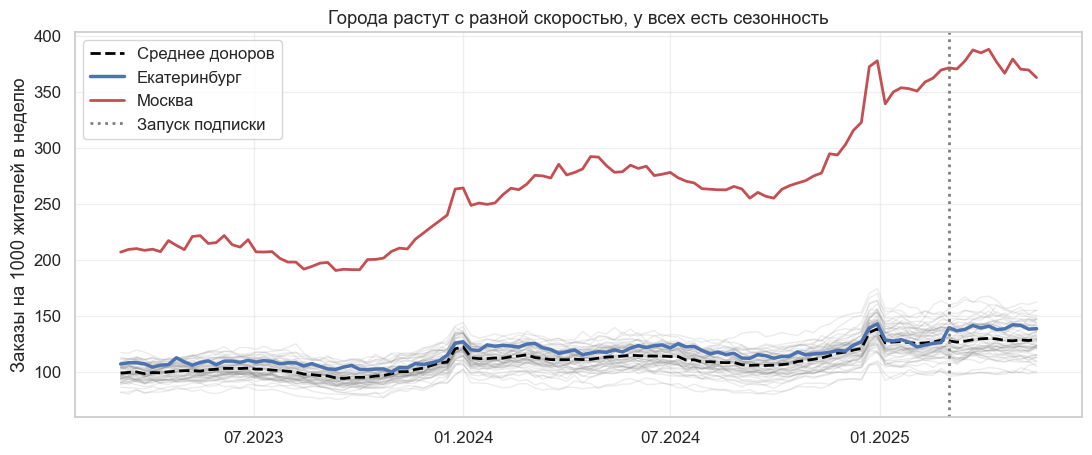

In [3]:
fig, ax = plt.subplots(figsize=(13, 5))
for city in POOL:
    ax.plot(orders.index, orders[city], color=GRAY, alpha=0.15, lw=1)
ax.plot(orders.index, orders[POOL].mean(axis=1), color="black", lw=2, ls="--", label="Среднее доноров")
ax.plot(orders.index, orders[TREATED], color=BLUE, lw=2.5, label=TREATED)
ax.plot(orders.index, orders[OUTLIER], color=RED, lw=2, label=OUTLIER)
ax.axvline(LAUNCH, color=GRAY, ls=":", lw=2, label="Запуск подписки")
ax.set_ylabel("Заказы на 1000 жителей в неделю")
ax.set_title("Города растут с разной скоростью, у всех есть сезонность")
ax.legend(loc="upper left")
date_axis(ax);

## 1. Почему не DiD

Самый простой вариант: взять соседний город или среднее всех городов и посчитать разность разностей.

### Задание 1. DiD и его проверка

Реализуйте `did_percent(y, treated, controls, start, window)`. Функция считает относительную DiD-оценку в процентах по `window` недель после номера недели `start` и `window` недель перед ним:

$$\widehat{DiD} = 100 \cdot \frac{(\bar y^{\,post}_{T} - \bar y^{\,post}_{C}) - (\bar y^{\,pre}_{T} - \bar y^{\,pre}_{C})}{\bar y^{\,pre}_{T}}$$

Здесь $C$ — среднее по городам из `controls`. Такая функция годится и для настоящей даты запуска, и для ложной.

In [4]:
def did_percent(y: pd.DataFrame, treated: str, controls: list, start: int, window: int = 12) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [5]:
# @title Решение (нажмите, чтобы раскрыть)
def did_percent(y: pd.DataFrame, treated: str, controls: list, start: int, window: int = 12) -> float:
    gap = y[treated].values - y[controls].mean(axis=1).values
    pre, post = np.arange(start - window, start), np.arange(start, start + window)
    return float(100 * (gap[post].mean() - gap[pre].mean()) / y[treated].values[pre].mean())

In [6]:
# Проверка: в ряду с постоянной разницей оценка равна нулю, а скачок на 10% возвращается
check = pd.DataFrame({"a": np.full(40, 100.0), "b": np.full(40, 80.0)})
assert abs(did_percent(check, "a", ["b"], 20)) < 1e-9
check.loc[20:, "a"] += 10
assert abs(did_percent(check, "a", ["b"], 20) - 10) < 1e-9
print("OK")

OK


Настоящая оценка сама по себе ничего не говорит. Поэтому посчитаем DiD ещё и на **ложных датах**, когда подписки не было. Там любая «оценка» — чистая ошибка метода. Если ошибка велика по сравнению с точкой окупаемости, настоящей оценке верить нельзя.

In [7]:
groups = {"Челябинск": ["Челябинск"], "Воронеж": ["Воронеж"], "Самара": ["Самара"], "Среднее всех доноров": POOL}
fake_starts = range(30, T0 - 24, 4)
rows = []
for name, controls in groups.items():
    fake = [did_percent(orders, TREATED, controls, s) for s in fake_starts]
    rows.append({"Контроль": name, "Оценка на дате запуска": did_percent(orders, TREATED, controls, T0),
                 "Ошибка на ложных датах, SD": np.std(fake), "Средняя ошибка": np.mean(fake)})
did_table = pd.DataFrame(rows).set_index("Контроль")
did_table

,Оценка на дате запуска,"Ошибка на ложных датах, SD",Средняя ошибка
Контроль,,,
Челябинск,14.45,3.29,0.09
Воронеж,5.60,5.59,-1.26
Самара,8.85,2.45,0.77
Среднее всех доноров,7.53,2.67,0.06


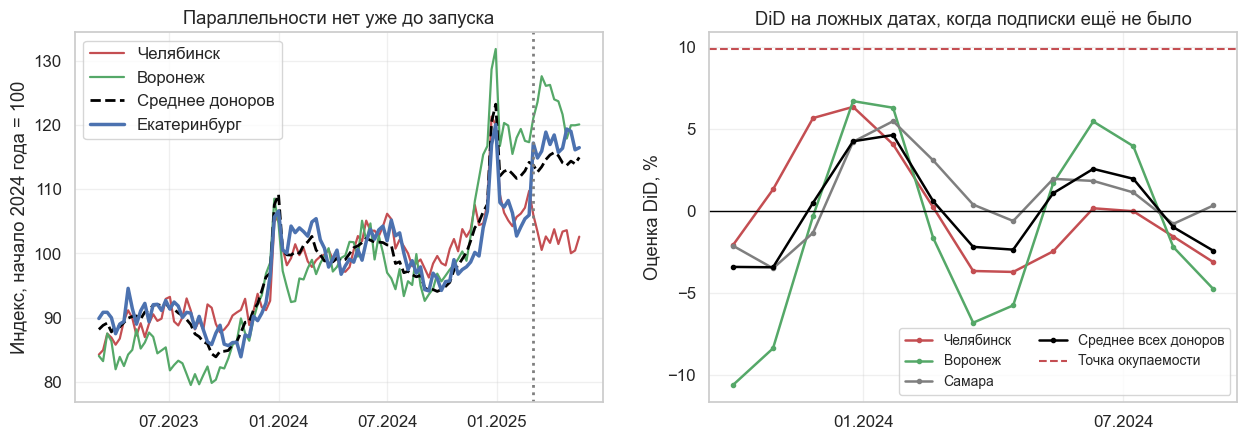

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
index = 100 * orders / orders.iloc[T0 - 52:T0 - 39].mean()
for name, color in [("Челябинск", RED), ("Воронеж", GREEN)]:
    axes[0].plot(index.index, index[name], color=color, lw=1.6, label=name)
axes[0].plot(index.index, index[POOL].mean(axis=1), color="black", ls="--", lw=2, label="Среднее доноров")
axes[0].plot(index.index, index[TREATED], color=BLUE, lw=2.5, label=TREATED)
axes[0].axvline(LAUNCH, color=GRAY, ls=":", lw=2)
axes[0].set_ylabel("Индекс, начало 2024 года = 100")
axes[0].set_title("Параллельности нет уже до запуска")
axes[0].legend()
date_axis(axes[0])

for (name, controls), color in zip(groups.items(), [RED, GREEN, GRAY, "black"]):
    axes[1].plot(orders.index[list(fake_starts)], [did_percent(orders, TREATED, controls, s) for s in fake_starts],
                 color=color, lw=1.8, marker="o", ms=3, label=name)
axes[1].axhline(0, color="black", lw=1)
axes[1].axhline(BREAK_EVEN, color=RED, ls="--", label="Точка окупаемости")
axes[1].set_ylabel("Оценка DiD, %")
axes[1].set_title("DiD на ложных датах, когда подписки ещё не было")
axes[1].legend(ncol=2, fontsize=10)
date_axis(axes[1]);

Оценки лежат от +5.6% до +14.5%, то есть по обе стороны точки окупаемости +9.9%. Решение определяет выбранный контроль.

На ложных датах среднее ошибки близко к нулю, поэтому постоянного смещения у DiD здесь нет. Проблема в размахе: SD ошибки от 2.5 до 5.6 п.п., а Воронеж уходит до −10% там, где никакого запуска не было. Города по-разному переживают сезоны и разными темпами растут, поэтому параллельности нет даже у среднего всех доноров. Ещё нет ответа, какой контроль правильный: выбрав город под ответ, мы подгоним результат.

## 2. Свой синтетический контроль

Напомним идею из лекции 2.09. Ищем веса доноров $w_j \ge 0$, $\sum_j w_j = 1$, при которых взвешенное среднее повторяет город запуска до старта. Веса подбираем не по самим рядам напрямую, а по **предикторам**:

$$w^* = \arg\min_{w} \sum_{h=1}^{k} v_h \Big(x_{h1} - \sum_{j} w_j x_{hj}\Big)^2$$

Здесь $x_{hj}$ — значение предиктора $h$ у города $j$, а $v_h$ — важность предиктора. Ограничения на веса запрещают экстраполяцию: синтетика остаётся внутри выпуклой оболочки доноров.

Эффект считаем в процентах от синтетики, чтобы сравнивать города разного размера:

$$\text{gap}_t = 100 \cdot \frac{Y_{1t} - \sum_j w^*_j Y_{jt}}{\sum_j w^*_j Y_{jt}}$$

### Задание 2. Веса

Реализуйте `fit_weights(x1, X0, v)`. Минимизируйте функционал через `scipy.optimize.minimize` с методом `SLSQP`. Передайте аналитический градиент: на 56 донорах и тысячах запусков это заметно ускорит расчёт. Строки `X0` — предикторы, столбцы — доноры, `v` по умолчанию единичный.

In [9]:
def fit_weights(x1: np.ndarray, X0: np.ndarray, v: np.ndarray = None) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [10]:
# @title Решение (нажмите, чтобы раскрыть)
def fit_weights(x1: np.ndarray, X0: np.ndarray, v: np.ndarray = None) -> np.ndarray:
    v = np.ones(len(x1)) if v is None else np.asarray(v, dtype=float)
    H, g = (X0.T * v) @ X0, (X0.T * v) @ x1
    n = X0.shape[1]
    result = minimize(lambda w: 0.5 * w @ H @ w - g @ w, np.full(n, 1 / n), jac=lambda w: H @ w - g,
                      bounds=[(0, 1)] * n, method="SLSQP",
                      constraints={"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)},
                      options={"maxiter": 500, "ftol": 1e-10})
    return result.x

In [11]:
# Проверка: восстанавливаем известную смесь и не выходим за ограничения
rng = np.random.default_rng(3)
X_check = rng.normal(size=(30, 6))
true_w = np.array([0.5, 0.3, 0.2, 0, 0, 0])
found = fit_weights(X_check @ true_w, X_check)
assert np.allclose(found, true_w, atol=1e-3)
outside = fit_weights(X_check @ np.array([2.0, -1, 0, 0, 0, 0]), X_check)
assert outside.min() > -1e-8 and abs(outside.sum() - 1) < 1e-8
print("OK")

OK


### Задание 3. Что считать предикторами

Взять все 104 недели как 104 предиктора кажется естественным, но у этого есть две цены. Синтетика начинает подгонять недельный шум. Кроме того, [Kaul et al.](https://mpra.ub.uni-muenchen.de/83790/1/MPRA_paper_83790.pdf) доказали: если все прошлые значения метрики идут отдельными предикторами, то оптимизируется только подгонка по метрике, а остальные ковариаты перестают влиять на результат, какими бы важными они ни были.

Поэтому усредним ряд по блокам в `block` недель. Абади (2021) предлагает выбирать такие настройки на самих данных: разделить предпериод на обучающую и проверочную части, подобрать веса на первой и посмотреть ошибку на второй.

Реализуйте `block_means(a, block)`: на вход массив, где по строкам идут недели, на выходе средние по последовательным блокам. Блоки считаются **с конца**, неполный блок в начале отбрасывается, потому что последние недели перед запуском важнее.

In [12]:
def block_means(a: np.ndarray, block: int) -> np.ndarray:
    # ВАШ КОД
    raise NotImplementedError

In [13]:
# @title Решение (нажмите, чтобы раскрыть)
def block_means(a: np.ndarray, block: int) -> np.ndarray:
    n_blocks = len(a) // block
    trimmed = a[len(a) - n_blocks * block:]
    return trimmed.reshape(n_blocks, block, *a.shape[1:]).mean(axis=1)

In [14]:
# Проверка
assert block_means(np.arange(7.0), 3).tolist() == [2.0, 5.0]
assert block_means(np.arange(12.0).reshape(6, 2), 3).shape == (2, 2)
print("OK")

OK


Соберём всё в одну функцию. Она понадобится сотни раз, поэтому пусть возвращает всё, что нам нужно для проверок: разрыв в процентах, синтетику и веса. Параметр `fit_end` задаёт, сколько первых недель видит подгонка, а параметр `covariates` добавляет статические признаки города.

In [15]:
SC = namedtuple("SC", "gap synthetic weights")
BLOCK = 4


def synth(y: pd.DataFrame, city: str, donors: list, fit_end: int = T0, block: int = BLOCK,
          covariates: pd.DataFrame = None, cov_importance: float = 1.0) -> SC:
    """Строит синтетический контроль города и возвращает разрыв в процентах по всем неделям."""
    x1 = block_means(y[city].values[:fit_end], block)
    X0 = block_means(y[donors].values[:fit_end], block)
    v = np.ones(len(x1))
    if covariates is not None:
        scale = covariates.loc[donors].std() / y[donors].values[:fit_end].std()
        extra = covariates / scale
        x1 = np.r_[x1, extra.loc[city].values]
        X0 = np.vstack([X0, extra.loc[donors].values.T])
        v = np.r_[v, np.full(extra.shape[1], cov_importance)]
    weights = pd.Series(fit_weights(x1, X0, v), index=donors)
    synthetic = pd.Series(y[donors].values @ weights.values, index=y.index)
    return SC(100 * (y[city] - synthetic) / synthetic, synthetic, weights)


def rmspe(gap) -> float:
    return float(np.sqrt(np.mean(np.square(gap))))

### Задание 4. Выбор блока на отложенных данных

Реализуйте `validation_rmspe(y, city, donors, train_end, valid_end, block)`: подгоните веса на первых `train_end` неделях и верните RMSPE разрыва на неделях с `train_end` по `valid_end`. Затем сравните блоки 1, 2, 4, 13, 26 и 52 недели.

Обучение идёт на первых 52 неделях, проверка на следующих 48. Последние 4 недели предпериода мы пока не трогаем: они ещё пригодятся.

In [16]:
def validation_rmspe(y: pd.DataFrame, city: str, donors: list, train_end: int, valid_end: int, block: int) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [17]:
# @title Решение (нажмите, чтобы раскрыть)
def validation_rmspe(y: pd.DataFrame, city: str, donors: list, train_end: int, valid_end: int, block: int) -> float:
    gap = synth(y, city, donors, fit_end=train_end, block=block).gap
    return rmspe(gap.values[train_end:valid_end])

In [18]:
# Проверка: на ряду, который точно равен донору, ошибка на отложенных данных нулевая
check = pd.DataFrame({"a": np.arange(30.0) + 50, "b": np.arange(30.0) + 50, "c": 80 - np.arange(30.0) * 2})
assert validation_rmspe(check, "a", ["b", "c"], 20, 30, 2) < 1e-3
blocks = [1, 2, 4, 13, 26, 52]
block_rows = []
for b in blocks:
    train_fit = synth(orders, TREATED, POOL, fit_end=52, block=b)
    block_rows.append({"Блок, недель": b, "Предикторов": 52 // b, "RMSPE на обучении, %": rmspe(train_fit.gap.values[:52]),
                       "RMSPE на проверке, %": validation_rmspe(orders, TREATED, POOL, 52, 100, b),
                       "Доноров с весом > 1%": int((train_fit.weights > 0.01).sum())})
block_table = pd.DataFrame(block_rows).set_index("Блок, недель")
block_table

,Предикторов,"RMSPE на обучении, %","RMSPE на проверке, %",Доноров с весом > 1%
"Блок, недель",,,,
1,52,1.32,1.99,6
2,26,1.33,1.87,5
4,13,1.41,1.82,5
13,4,2.02,2.47,18
26,2,2.35,2.73,6
52,1,2.63,3.09,56


Ошибка на проверке минимальна у блока 4 недели: 1.82%. Блок 1 неделя лучше всех подгоняет обучение (1.32%), но проигрывает на проверке (1.99%): это начало переобучения. Блоки от 13 недель стирают сезонность, и ошибка растёт до 2.5–3.1%. При блоке 52 недели остаётся один предиктор, и задача вообще перестаёт определять веса.

Берём **блок 4 недели** и дальше его не меняем. Мы выбрали его на данных до запуска, не глядя на эффект.

### Что с ковариатами

Абади предостерегает от привычки опираться только на прошлые значения метрики: другие предикторы тоже важны. Проверим на нашем городе, что меняется, если добавить доход и долю молодых при блоках по 4 недели.

In [19]:
covariates = cities[["income_index", "young_share"]]
rows = [{"Спецификация": TREATED, **covariates.loc[TREATED].to_dict()}]
for name, kwargs in {"Без ковариат": {}, "С ковариатами": {"covariates": covariates}}.items():
    fit = synth(orders, TREATED, POOL, **kwargs)
    rows.append({"Спецификация": name, **(covariates.loc[POOL].T @ fit.weights).to_dict(),
                 "RMSPE до запуска, %": rmspe(fit.gap.values[:T0]), "Эффект, %": fit.gap.values[T0:].mean()})
pd.DataFrame(rows).set_index("Спецификация")

,income_index,young_share,"RMSPE до запуска, %","Эффект, %"
Спецификация,,,,
Екатеринбург,108.40,0.23,NaN,NaN
Без ковариат,109.40,0.24,1.71,11.70
С ковариатами,106.79,0.23,1.98,13.94


Ковариаты здесь не помогают. Синтетика и без них похожа на город: индекс дохода 109.4 при 108.4 у Екатеринбурга, а с ковариатами он отходит до 106.8, и ошибка до запуска растёт с 1.71% до 1.98%. Прошлые значения метрики уже несут информацию о доходе. Оставляем только их.

Заметьте, что оценка сдвинулась с +11.7% до +13.9%. Спецификация, которая кажется технической деталью, двигает ответ на 2 п.п. К этому мы вернёмся в разделе 7.

## 3. Первый результат

Подгоним веса на всём предпериоде и посмотрим на результат.

Эффект подписки: +11.7% при точке окупаемости +9.9%
t-тест разрыва по 12 неделям: p = 5.3e-08
Доноры: {'Сургут': 0.465, 'Красноярск': 0.319, 'Челябинск': 0.136, 'Курган': 0.073}


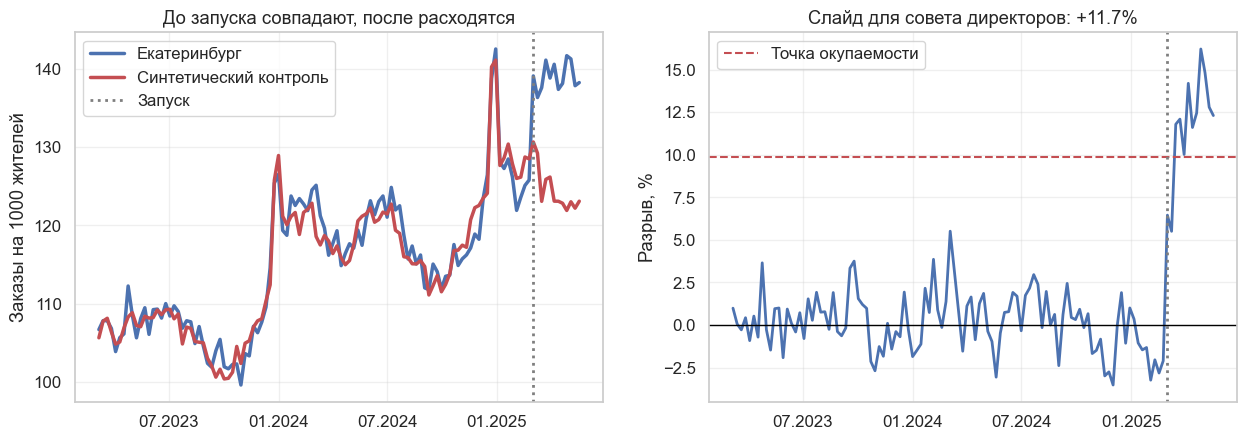

In [20]:
first = synth(orders, TREATED, POOL)
first_effect = first.gap.values[T0:].mean()
post_t = stats.ttest_1samp(first.gap.values[T0:], 0)
print(f"Эффект подписки: +{first_effect:.1f}% при точке окупаемости +{BREAK_EVEN:.1f}%")
print(f"t-тест разрыва по 12 неделям: p = {post_t.pvalue:.1e}")
print("Доноры:", first.weights[first.weights > 0.01].sort_values(ascending=False).round(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(orders.index, orders[TREATED], color=BLUE, lw=2.5, label=TREATED)
axes[0].plot(orders.index, first.synthetic, color=RED, lw=2.5, label="Синтетический контроль")
axes[0].axvline(LAUNCH, color=GRAY, ls=":", lw=2, label="Запуск")
axes[0].set_ylabel("Заказы на 1000 жителей")
axes[0].set_title("До запуска совпадают, после расходятся")
axes[0].legend()
axes[1].plot(orders.index, first.gap, color=BLUE, lw=2)
axes[1].axhline(0, color="black", lw=1)
axes[1].axhline(BREAK_EVEN, color=RED, ls="--", label="Точка окупаемости")
axes[1].axvline(LAUNCH, color=GRAY, ls=":", lw=2)
axes[1].set_ylabel("Разрыв, %")
axes[1].set_title(f"Слайд для совета директоров: +{first_effect:.1f}%")
axes[1].legend()
date_axis(*axes);

Выглядит отлично: эффект +11.7% выше точки окупаемости +9.9%, до запуска ряды совпадают с ошибкой 1.7%, t-тест даёт $p = 5 \cdot 10^{-8}$. Продакт готовит слайд.

**Вопрос.** Что не так с этим t-тестом, даже если не сомневаться в синтетике?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Сразу две вещи. Недельные разрывы не независимы: синтетика ошиблась, например, в тренде, и эта ошибка держится неделями, поэтому 12 точек несут гораздо меньше информации, чем 12 независимых наблюдений. Кроме того, этот тест сравнивает разрыв с нулём и не учитывает, что сама синтетика — оценка, а веса подбирались под этот город. В разделе 8 мы измерим, как часто такой тест ошибается, когда эффекта нет.

</details>

Дальше будем считать эту оценку **гипотезой, а не результатом**, и пройдём пять вопросов:

| Раздел | Вопрос | Если ответ «нет» |
|---|---|---|
| 4 | Применим ли метод к этой задаче? | Не считаем дальше |
| 5 | Хорошо ли синтетика воспроизводит город на данных, которых не видела? | Оценка смещена |
| 6 | Выделяется ли разрыв на фоне шума? | Эффект не доказан |
| 7 | Устойчив ли результат к решениям аналитика? | Эффект создан спецификацией |
| 8 | Находит ли метод эффект там, где он есть, и молчит ли там, где его нет? | Выводы метода ненадёжны |

## 4. Применим ли метод

Абади (2021) начинает не с формул, а с контекста. Часть условий проверяется только разговором с командой:

* **Нет ожиданий.** Если клиенты узнали о подписке заранее, запуск начался раньше своей даты.
* **Нет интерференции.** Запуск не влияет на доноров. Иначе контроль загрязнён.
* **Чистый пул.** У доноров не было похожих воздействий и крупных собственных шоков.

Другую часть можно проверить на данных до запуска.

### Задание 5. Хватит ли сигнала

Эффект должен быть заметен на фоне обычных колебаний города. Реализуйте `signal_table(y, cities_list, fit_end)`. Для каждого города возьмите разность логарифмов с тем же значением годом раньше, `log y[t] - log y[t-52]`: она убирает сезонность. Затем вычтите линейный тренд и верните SD остатка в процентах.

In [21]:
def signal_table(y: pd.DataFrame, cities_list: list, fit_end: int = T0) -> pd.Series:
    # ВАШ КОД
    raise NotImplementedError

In [22]:
# @title Решение (нажмите, чтобы раскрыть)
def signal_table(y: pd.DataFrame, cities_list: list, fit_end: int = T0) -> pd.Series:
    log_y = np.log(y[cities_list].values[:fit_end])
    yearly = log_y[52:] - log_y[:-52]
    time = np.arange(len(yearly))
    trend = np.polyfit(time, yearly, 1)
    fitted = np.outer(time, trend[0]) + trend[1]
    return pd.Series(100 * (yearly - fitted).std(axis=0), index=cities_list)

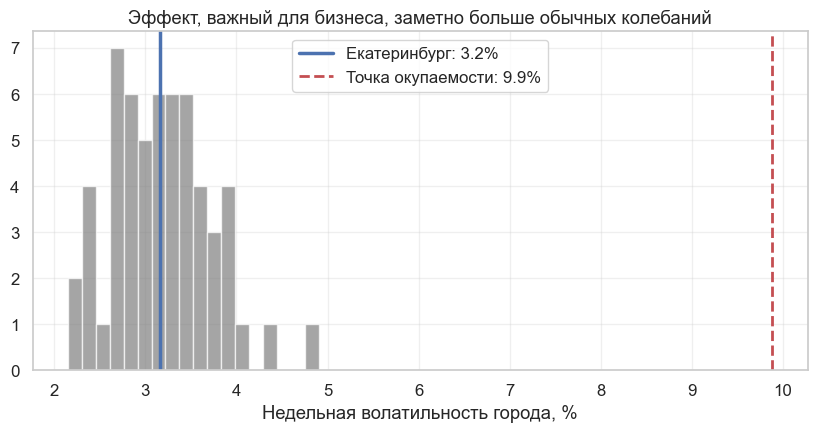

In [23]:
# Проверка: у чистого линейного логарифма остаток нулевой
check = pd.DataFrame({"a": np.exp(0.01 * np.arange(110.0))})
assert signal_table(check, ["a"], 104)["a"] < 1e-8

volatility = signal_table(orders, POOL + [TREATED])
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.hist(volatility, bins=18, color=GRAY, alpha=0.7)
ax.axvline(volatility[TREATED], color=BLUE, lw=2.5, label=f"{TREATED}: {volatility[TREATED]:.1f}%")
ax.axvline(BREAK_EVEN, color=RED, ls="--", lw=2, label=f"Точка окупаемости: {BREAK_EVEN:.1f}%")
ax.set_xlabel("Недельная волатильность города, %")
ax.set_title("Эффект, важный для бизнеса, заметно больше обычных колебаний")
ax.legend();

Обычные колебания города составляют около 3%, а точка окупаемости 9.9%, то есть втрое больше. Значит, эффект нужного масштаба в принципе различим, а вот рост на 2–3% утонул бы в шуме. Это грубая оценка, точную мощность измерим в разделе 8.

### Задание 6. Лежит ли город среди доноров

Синтетика не может выйти за выпуклую оболочку доноров. Если город растёт быстрее всех или заказывает больше всех, никакие веса его не догонят. Проверка простая: сравним уровень и темп роста города с диапазоном доноров.

Реализуйте `hull_position(y, city, donors, fit_end)`. Для города и каждого донора посчитайте средний уровень за последние 26 недель и рост за год в процентах (среднее последних 26 недель к тем же неделям годом раньше). Верните таблицу со столбцами `level` и `growth`, индекс — города.

In [24]:
def hull_position(y: pd.DataFrame, city: str, donors: list, fit_end: int = T0) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [25]:
# @title Решение (нажмите, чтобы раскрыть)
def hull_position(y: pd.DataFrame, city: str, donors: list, fit_end: int = T0) -> pd.DataFrame:
    frame = y[[city] + donors]
    last = frame.iloc[fit_end - 26:fit_end].mean()
    year_ago = frame.iloc[fit_end - 78:fit_end - 52].mean()
    return pd.DataFrame({"level": last, "growth": 100 * (last / year_ago - 1)})

Эффект, который «нашёл» бы метод в Москве без всякого запуска: +132%


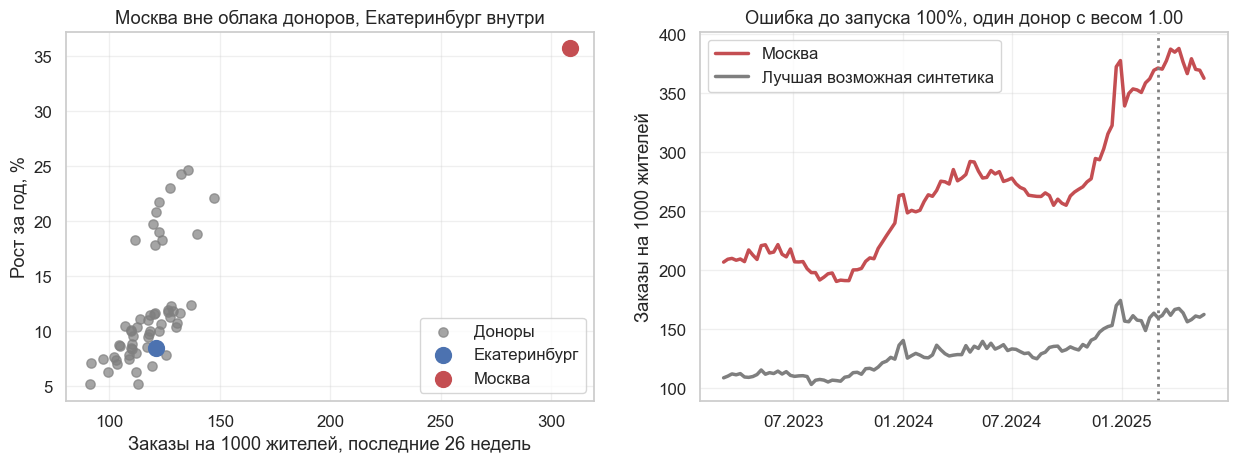

In [26]:
# Проверка
position = hull_position(orders, TREATED, POOL + [OUTLIER])
assert position.shape == (len(POOL) + 2, 2)
assert position.loc[OUTLIER, "level"] > position["level"].drop(OUTLIER).max()

outlier_fit = synth(orders, OUTLIER, POOL)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
donors_pos = position.drop([TREATED, OUTLIER])
axes[0].scatter(donors_pos["level"], donors_pos["growth"], color=GRAY, s=45, alpha=0.7, label="Доноры")
axes[0].scatter(*position.loc[TREATED], color=BLUE, s=130, label=TREATED, zorder=3)
axes[0].scatter(*position.loc[OUTLIER], color=RED, s=130, label=OUTLIER, zorder=3)
axes[0].set_xlabel("Заказы на 1000 жителей, последние 26 недель")
axes[0].set_ylabel("Рост за год, %")
axes[0].set_title("Москва вне облака доноров, Екатеринбург внутри")
axes[0].legend(loc="lower right")
axes[1].plot(orders.index, orders[OUTLIER], color=RED, lw=2.5, label=OUTLIER)
axes[1].plot(orders.index, outlier_fit.synthetic, color=GRAY, lw=2.5, label="Лучшая возможная синтетика")
axes[1].axvline(LAUNCH, color=GRAY, ls=":", lw=2)
axes[1].set_ylabel("Заказы на 1000 жителей")
axes[1].set_title(f"Ошибка до запуска {rmspe(outlier_fit.gap.values[:T0]):.0f}%, один донор с весом {outlier_fit.weights.max():.2f}")
axes[1].legend()
date_axis(axes[1])
print("Эффект, который «нашёл» бы метод в Москве без всякого запуска:", f"{outlier_fit.gap.values[T0:].mean():+.0f}%")

Екатеринбург лежит внутри облака доноров. С Москвой всё иначе: она заказывает больше всех и растёт быстрее всех. Лучшее, что могут веса, — отдать единицу одному городу. Ошибка до запуска 100%, а «эффект» +132% появляется без всякого запуска.

Хорошо, что это видно **до** чтения результата. Если бы подписку запустили в Москве, единственный честный ответ — **синтетический контроль здесь оценить ничего не может**. Эту проверку стоит делать ещё на этапе выбора города.

## 5. Качество подгонки

Малая ошибка до запуска — необходимое условие, но не достаточное: подгонку на обучении легко сделать сколь угодно хорошей. Нас интересует, как синтетика ведёт себя **на неделях, которых не видела**.

### Задание 7. Отложенная проверка и простые прогнозы

Реализуйте `holdout_report(y, city, donors, train_end, valid_end)`. Подгоните веса на первых `train_end` неделях и посчитайте RMSPE в процентах на неделях проверки для трёх способов прогноза:

1. **Синтетика**: `synth(...)`.
2. **Среднее доноров с поправкой на уровень**: среднее всех доноров, умноженное на отношение средних города и доноров на обучении.
3. **Сезонный наивный прогноз**: значение годом раньше, умноженное на рост последних 26 недель обучения к тем же неделям годом раньше.

Верните словарь `{название: RMSPE}`. Синтетика имеет право на жизнь, только если она лучше простых способов.

In [27]:
def holdout_report(y: pd.DataFrame, city: str, donors: list, train_end: int, valid_end: int) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [28]:
# @title Решение (нажмите, чтобы раскрыть)
def holdout_report(y: pd.DataFrame, city: str, donors: list, train_end: int, valid_end: int) -> dict:
    actual = y[city].values
    weeks = np.arange(train_end, valid_end)
    fit = synth(y, city, donors, fit_end=train_end)

    donors_mean = y[donors].mean(axis=1).values
    scaled = donors_mean * actual[:train_end].mean() / donors_mean[:train_end].mean()

    growth = actual[train_end - 26:train_end].mean() / actual[train_end - 78:train_end - 52].mean()
    seasonal = actual[weeks - 52] * growth

    def error(forecast):
        return rmspe(100 * (actual[weeks] - forecast) / forecast)

    return {"Синтетика": rmspe(fit.gap.values[weeks]), "Среднее доноров": error(scaled[weeks]), "Сезонный наивный": error(seasonal)}

In [29]:
# Проверка: ряд, идеально собранный из доноров, синтетика воспроизводит лучше всех
check = orders[POOL[:6]].copy()
check["x"] = 0.6 * check[POOL[0]] + 0.4 * check[POOL[1]]
result = holdout_report(check, "x", POOL[:6], 78, 100)
assert result["Синтетика"] < 0.1 and result["Синтетика"] < min(result["Среднее доноров"], result["Сезонный наивный"])

holdout = pd.DataFrame({
    "Обучение до недели 78": holdout_report(orders, TREATED, POOL, 78, 100),
    "Обучение до недели 90": holdout_report(orders, TREATED, POOL, 90, 100)}).T
print("RMSPE на проверке до недели 100, %")
holdout

RMSPE на проверке до недели 100, %


,Синтетика,Среднее доноров,Сезонный наивный
Обучение до недели 78,2.00,3.44,2.78
Обучение до недели 90,2.35,4.52,3.74


Синтетика лучше обоих простых способов: 2.0–2.4% против 3.4–4.5% у среднего доноров и 2.8–3.7% у сезонного прогноза. Ошибка на проверке выше, чем на обучении (около 1.5%), но разница небольшая, значит, сильного переобучения нет. Проверка пройдена.

### Задание 8. На кого похожа синтетика

Веса тоже проверяем. Если синтетика опирается на одного донора, результат зависит от его судьбы. Если она собрана из городов, которые трудно объяснить, стоит задуматься, не подгонка ли это.

Реализуйте `weight_report(weights)`. Верните эффективное число доноров $1 / \sum_j w_j^2$, долю крупнейшего донора и долю трёх крупнейших.

In [30]:
def weight_report(weights: pd.Series) -> dict:
    # ВАШ КОД
    raise NotImplementedError

In [31]:
# @title Решение (нажмите, чтобы раскрыть)
def weight_report(weights: pd.Series) -> dict:
    ordered = weights.sort_values(ascending=False)
    return {"Эффективное число доноров": float(1 / (weights ** 2).sum()), "Крупнейший донор": float(ordered.iloc[0]),
            "Три крупнейших": float(ordered.iloc[:3].sum())}

{'Эффективное число доноров': 2.92, 'Крупнейший донор': 0.46, 'Три крупнейших': 0.92}
Средний разрыв за 4 недели до запуска: -2.55%


,Екатеринбург,Синтетика,Среднее доноров,SD доноров
income_index,108.40,109.40,100.81,12.04
young_share,0.23,0.24,0.24,0.02


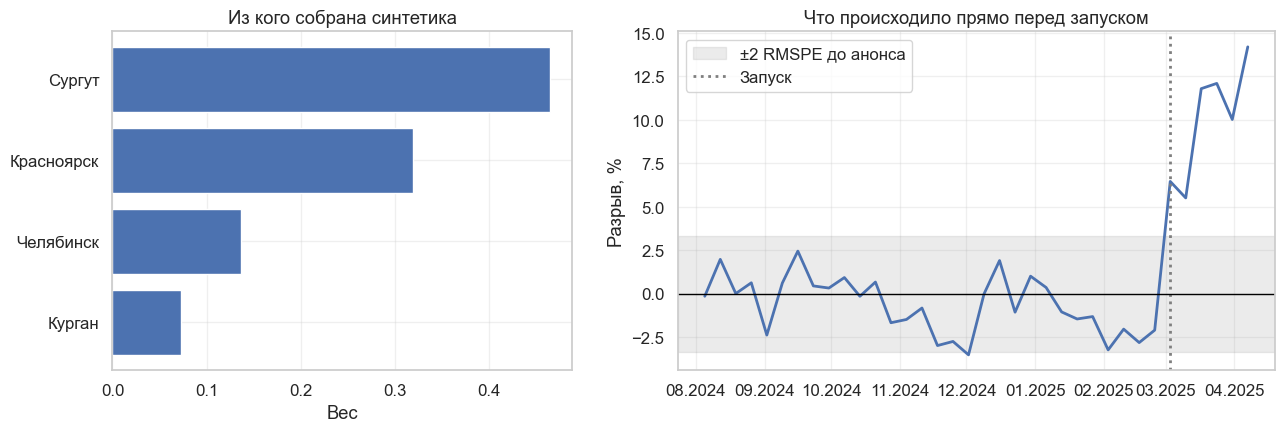

In [32]:
# Проверка
assert np.isclose(weight_report(pd.Series([0.25] * 4))["Эффективное число доноров"], 4)
assert weight_report(pd.Series([1.0, 0, 0]))["Крупнейший донор"] == 1

print({k: round(v, 2) for k, v in weight_report(first.weights).items()})
top = first.weights[first.weights > 0.01].sort_values(ascending=False)
balance = pd.DataFrame({"Екатеринбург": covariates.loc[TREATED], "Синтетика": covariates.loc[POOL].T @ first.weights,
                        "Среднее доноров": covariates.loc[POOL].mean(), "SD доноров": covariates.loc[POOL].std()})
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].barh(top.index[::-1], top.values[::-1], color=BLUE)
axes[0].set_xlabel("Вес")
axes[0].set_title("Из кого собрана синтетика")
recent = first.gap.iloc[T0 - 30:T0 + 6]
axes[1].axhspan(-2 * rmspe(first.gap.values[:T0 - 4]), 2 * rmspe(first.gap.values[:T0 - 4]), color=GRAY, alpha=0.15, label="±2 RMSPE до анонса")
axes[1].plot(recent.index, recent, color=BLUE, lw=2)
axes[1].axvline(LAUNCH, color=GRAY, ls=":", lw=2, label="Запуск")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_ylabel("Разрыв, %")
axes[1].set_title("Что происходило прямо перед запуском")
axes[1].legend()
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
print(f"Средний разрыв за 4 недели до запуска: {first.gap.values[T0 - 4:T0].mean():+.2f}%")
balance

Что видно:

* **Концентрация.** Эффективное число доноров 2.9, а три города дают 92% веса. Синтетика фактически состоит из трёх городов, и судьба каждого важна для результата.
* **Баланс.** По доходу и доле молодых синтетика близка к городу (109.4 против 108.4 и 0.24 против 0.23), хотя среднее доноров заметно отличается (100.8).
* **Соседи.** Челябинск и Курган с Екатеринбургом в одном регионе. Поэтому они хорошо его повторяют, но и риск интерференции у них самый высокий. Запишем этот вопрос себе.
* **Перед запуском.** Все 4 недели перед запуском разрыв отрицательный, в среднем −2.5%. Это внутри обычного разброса, поэтому сам по себе сигнал слабый, но он настораживает.

**Вопрос.** Перед запуском разрыв упал. Почему это мешает, даже если сам провал небольшой?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Эти недели попали в подгонку как обычные данные, хотя на них город уже вёл себя иначе. Синтетику тянет вниз, и после запуска разрыв выглядит чуть больше. Важнее другое: если клиенты откладывали заказы до запуска, часть роста в первые недели после него — просто перенос, а не новый спрос. Абади советует в таком случае перенести дату воздействия на момент до анонса. Метод не требует, чтобы эффект был постоянным, поэтому такой перенос сам по себе ничего не ломает.

</details>

## 6. Выделяется ли разрыв на фоне шума

Единица воздействия одна, поэтому обычной дисперсии оценки у нас нет. Лекция 2.09 предлагает плацебо: притворимся, что подписку запустили в каждом из доноров.

### Задание 9. Плацебо по городам

Реализуйте `placebo_gaps(y, pool, treated, fit_end, block)`. Верните таблицу разрывов: строки — недели, столбцы — `treated` и все города из `pool`. Для `treated` доноры равны `pool`, для остальных — `pool` без самого города. Город запуска в доноры плацебо **не включаем**: он уже получил воздействие.

Затем реализуйте `placebo_summary(gaps, treated, fit_end, post_start)`. Для каждого города посчитайте эффект (средний разрыв после `post_start`), RMSPE до `fit_end`, RMSPE после `post_start` и их отношение. Верните таблицу, отсортированную по отношению.

In [33]:
def placebo_gaps(y: pd.DataFrame, pool: list, treated: str, fit_end: int = T0, block: int = BLOCK) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError


def placebo_summary(gaps: pd.DataFrame, treated: str, fit_end: int = T0, post_start: int = T0) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [34]:
# @title Решение (нажмите, чтобы раскрыть)
def placebo_gaps(y: pd.DataFrame, pool: list, treated: str, fit_end: int = T0, block: int = BLOCK) -> pd.DataFrame:
    gaps = {treated: synth(y, treated, pool, fit_end=fit_end, block=block).gap}
    for city in pool:
        donors = [c for c in pool if c != city]
        gaps[city] = synth(y, city, donors, fit_end=fit_end, block=block).gap
    return pd.DataFrame(gaps)


def placebo_summary(gaps: pd.DataFrame, treated: str, fit_end: int = T0, post_start: int = T0) -> pd.DataFrame:
    pre, post = gaps.values[:fit_end], gaps.values[post_start:]
    pre_rmspe = np.sqrt((pre ** 2).mean(axis=0))
    post_rmspe = np.sqrt((post ** 2).mean(axis=0))
    table = pd.DataFrame({"effect": post.mean(axis=0), "pre_rmspe": pre_rmspe, "post_rmspe": post_rmspe,
                          "ratio": post_rmspe / pre_rmspe}, index=gaps.columns)
    return table.sort_values("ratio", ascending=False)

In [35]:
first_gaps = placebo_gaps(orders, POOL, TREATED)
first_table = placebo_summary(first_gaps, TREATED)

# Проверка
assert first_gaps.shape == (len(orders), len(POOL) + 1)
assert np.isclose(first_table.loc[TREATED, "effect"], first_effect)


def placebo_p(table: pd.DataFrame, treated: str, column: str = "ratio") -> float:
    values = table[column].abs()
    return float((values >= values[treated]).mean())


print(f"p-value по отношению RMSPE: {placebo_p(first_table, TREATED):.3f}, по эффекту: {placebo_p(first_table, TREATED, 'effect'):.3f}, городов: {len(first_table)}")
first_table.head(6)

p-value по отношению RMSPE: 0.018, по эффекту: 0.018, городов: 57


,effect,pre_rmspe,post_rmspe,ratio
Екатеринбург,11.70,1.71,12.07,7.04
Красноярск,-11.27,2.40,12.74,5.31
Курган,-7.42,1.78,7.71,4.34
Томск,5.62,1.57,6.14,3.91
Санкт-Петербург,-7.29,2.32,7.64,3.29
Саратов,4.40,1.52,4.66,3.06


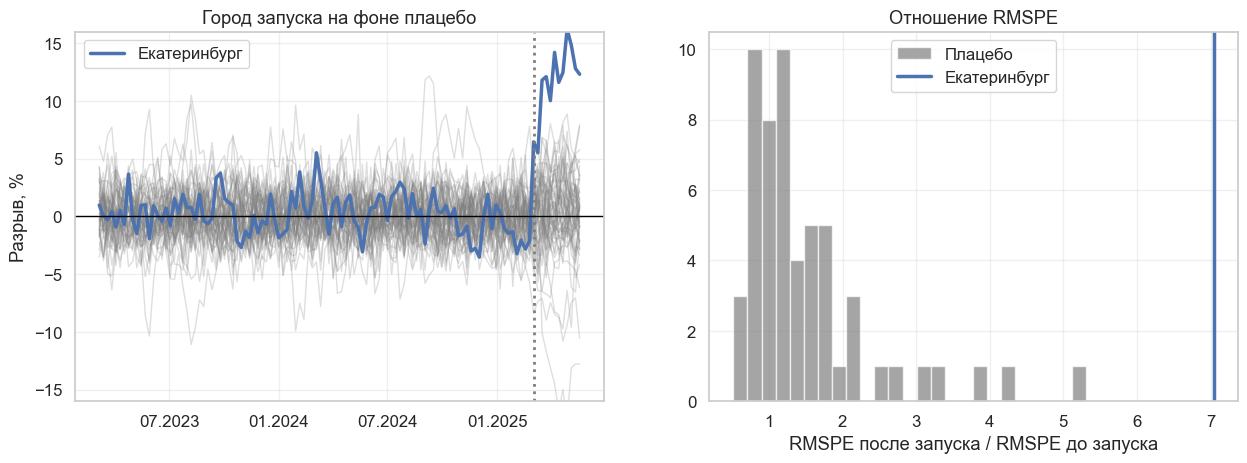

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
others = [c for c in first_gaps.columns if c != TREATED]
axes[0].plot(first_gaps.index, first_gaps[others].values, color=GRAY, alpha=0.25, lw=1)
axes[0].plot(first_gaps.index, first_gaps[TREATED], color=BLUE, lw=2.5, label=TREATED)
axes[0].axvline(LAUNCH, color=GRAY, ls=":", lw=2)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_ylim(-16, 16)
axes[0].set_ylabel("Разрыв, %")
axes[0].set_title("Город запуска на фоне плацебо")
axes[0].legend()
date_axis(axes[0])
axes[1].hist(first_table["ratio"].drop(TREATED), bins=25, color=GRAY, alpha=0.7, label="Плацебо")
axes[1].axvline(first_table.loc[TREATED, "ratio"], color=BLUE, lw=2.5, label=TREATED)
axes[1].set_xlabel("RMSPE после запуска / RMSPE до запуска")
axes[1].set_title("Отношение RMSPE")
axes[1].legend();

Екатеринбург на первом месте из 57 и по отношению RMSPE, и по эффекту, поэтому p-value равно минимально возможному 1/57 = 0.018.

Посмотрите на следующие строки таблицы. На втором и третьем местах стоят Красноярск и Курган с большими **отрицательными** эффектами, −11.3% и −7.4%. Это наши доноры. Пока просто запомним.

У этого p-value есть три ограничения, про которые важно помнить:

* **Минимальное значение равно $1/N$.** С 57 городами мы можем получить 0.018, но не меньше. Если городов 10, тест не покажет значимость на 5% никогда.
* **Это не настоящий перестановочный тест.** Такой тест требует, чтобы город запуска выбирался случайно. Город выбрали люди, поэтому [Arkhangelsky et al.](https://arxiv.org/abs/1812.09970) рекомендуют читать плацебо скорее качественно, а не как строгую гарантию.
* **Плацебо предполагает сравнимый шум у городов.** Если город запуска по природе шумнее или тише доноров, сравнение смещается.

### Задание 10. Бэкдейтинг

Плацебо по городам спрашивает «выделяется ли этот город». Плацебо по времени спрашивает другое: «умеет ли синтетика этого города молчать, когда ничего не происходит». Перенесём запуск в прошлое и подгоним веса только на данных до ложной даты. Если метод работает, разрыв останется около нуля вплоть до настоящей даты.

Реализуйте `backdating(y, city, donors, fake_ends)`. Для каждой ложной даты посчитайте разрыв и верните таблицу: строки — ложные даты, столбцы `pre_rmspe` (на неделях подгонки), `mean_gap` и `rmspe_gap` (с ложной даты до недели `T0 - 4`, то есть до анонса).

In [37]:
def backdating(y: pd.DataFrame, city: str, donors: list, fake_ends: list) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [38]:
# @title Решение (нажмите, чтобы раскрыть)
def backdating(y: pd.DataFrame, city: str, donors: list, fake_ends: list) -> pd.DataFrame:
    rows = {}
    for end in fake_ends:
        gap = synth(y, city, donors, fit_end=end).gap.values
        rows[end] = {"pre_rmspe": rmspe(gap[:end]), "mean_gap": gap[end:T0 - 4].mean(), "rmspe_gap": rmspe(gap[end:T0 - 4])}
    return pd.DataFrame(rows).T

,pre_rmspe,mean_gap,rmspe_gap
52,1.41,-0.56,1.82
65,1.47,0.16,1.85
78,1.48,-1.03,2.00
91,1.52,-1.84,2.39


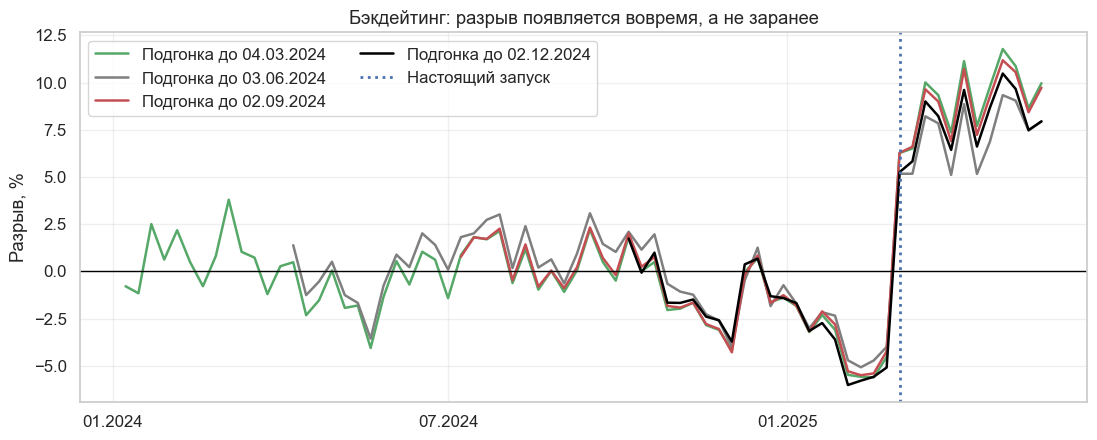

In [39]:
fake_ends = [52, 65, 78, 91]
back = backdating(orders, TREATED, POOL, fake_ends)

# Проверка
assert list(back.index) == fake_ends and {"pre_rmspe", "mean_gap", "rmspe_gap"} <= set(back.columns)

fig, ax = plt.subplots(figsize=(13, 4.8))
for end, color in zip(fake_ends, [GREEN, GRAY, RED, "black"]):
    gap = synth(orders, TREATED, POOL, fit_end=end).gap
    ax.plot(gap.index[end - 8:], gap.values[end - 8:], color=color, lw=1.8, label=f"Подгонка до {orders.index[end]:%d.%m.%Y}")
ax.axvline(LAUNCH, color=BLUE, ls=":", lw=2, label="Настоящий запуск")
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Разрыв, %")
ax.set_title("Бэкдейтинг: разрыв появляется вовремя, а не заранее")
ax.legend(ncol=2)
date_axis(ax)
back

На ложных датах средний разрыв от −1.8% до +0.2%, а ошибка 1.8–2.4% лишь немного выше, чем при подгонке. Даже когда подгонка закончилась на год раньше запуска, разрыв появляется ровно в момент запуска, и веса об этой дате ничего не знали. Проверка пройдена. Снова заметен небольшой провал прямо перед запуском.

### Задание 11. Конформный вывод

У плацебо по городам есть альтернатива, которой не нужны другие города как повторения: [Chernozhukov, Wüthrich, Zhu](https://arxiv.org/abs/1712.09089) сравнивают недели после запуска с неделями до него. Идея проверки гипотезы $H_0: \text{эффект} = \theta$:

1. Уберём из ряда города эффект $\theta$: на неделях после запуска поделим его на $1 + \theta / 100$. Если гипотеза верна, получится ряд без воздействия.
2. Подгоним веса на **всех** неделях, включая недели после запуска. При верной $H_0$ это законно, и именно это защищает от переобучения: неделям после запуска не с чего выглядеть хуже остальных.
3. Посчитаем остатки $\hat u_t$ и статистику $S = \big|\frac{1}{T_1}\sum_{t \in post} \hat u_t\big|$.
4. Сдвинем остатки по кругу на каждое из возможных смещений (**moving block**, порядок соседних недель сохраняется, поэтому автокорреляция не портит тест). Для каждого сдвига пересчитаем $S$.
5. P-value равно доле сдвигов, у которых $S$ не меньше исходного.

Перебрав сетку $\theta$ и оставив значения с $p > \alpha$, получим **доверительный интервал**. Это важно: плацебо по городам даёт только p-value, а решение зависит от сравнения с точкой окупаемости.

Одно отличие от статьи. Там базовая статистика — сумма модулей остатков, она ловит любое изменение. Мы проверяем постоянный средний эффект, поэтому берём модуль среднего: на наших данных он заметно чувствительнее. Раз мы поменяли рецепт, проверим его на A/A.

Реализуйте `conformal_p(y1, Y0, post, theta)` и `conformal_ci(y1, Y0, post, grid, alpha)`. Здесь `y1` — ряд города, `Y0` — матрица доноров, `post` — булева маска недель после запуска. Веса подбирайте по неделям напрямую.

In [40]:
def conformal_p(y1: np.ndarray, Y0: np.ndarray, post: np.ndarray, theta: float) -> float:
    # ВАШ КОД
    raise NotImplementedError


def conformal_ci(y1: np.ndarray, Y0: np.ndarray, post: np.ndarray, grid: np.ndarray, alpha: float = 0.1) -> tuple:
    # ВАШ КОД
    raise NotImplementedError

In [41]:
# @title Решение (нажмите, чтобы раскрыть)
def conformal_p(y1: np.ndarray, Y0: np.ndarray, post: np.ndarray, theta: float) -> float:
    adjusted = np.where(post, y1 / (1 + theta / 100), y1)
    weights = fit_weights(adjusted, Y0)
    fitted = Y0 @ weights
    residuals = 100 * (adjusted - fitted) / fitted
    statistics = np.array([abs(np.roll(residuals, shift)[post].mean()) for shift in range(len(y1))])
    return float((statistics >= statistics[0]).mean())


def conformal_ci(y1: np.ndarray, Y0: np.ndarray, post: np.ndarray, grid: np.ndarray, alpha: float = 0.1) -> tuple:
    p_values = np.array([conformal_p(y1, Y0, post, theta) for theta in grid])
    accepted = grid[p_values > alpha]
    return float(accepted.min()), float(accepted.max()), p_values

p-value при нулевом эффекте: 0.052
90%-интервал: [2.0%; 18.0%]


Доля ложных срабатываний на уровне 10% на A/A: 0.083 из 48 случаев


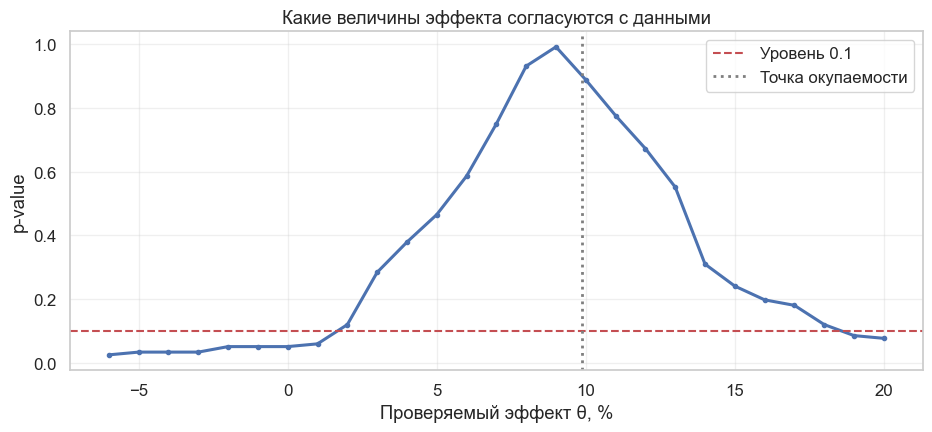

In [42]:
# Проверка: без эффекта p-value большое, а заложенный скачок 12% отвергается для нуля
rng = np.random.default_rng(11)
factor = np.cumsum(rng.normal(0, 1, 100)) + 100
Y_check = np.column_stack([factor + rng.normal(0, 0.3, 100) for _ in range(5)])
y_check = Y_check.mean(axis=1) + rng.normal(0, 0.2, 100)
post_check = np.arange(100) >= 88
assert conformal_p(y_check, Y_check, post_check, 0.0) > 0.1
jumped = np.where(post_check, y_check * 1.12, y_check)
assert conformal_p(jumped, Y_check, post_check, 0.0) < 0.05
assert conformal_p(jumped, Y_check, post_check, 12.0) > 0.1

post_mask = np.arange(len(orders)) >= T0
theta_grid = np.arange(-6.0, 21.0, 1.0)
low, high, curve = conformal_ci(orders[TREATED].values, orders[POOL].values, post_mask, theta_grid)
print(f"p-value при нулевом эффекте: {conformal_p(orders[TREATED].values, orders[POOL].values, post_mask, 0.0):.3f}")
print(f"90%-интервал: [{low:.1f}%; {high:.1f}%]")

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(theta_grid, curve, color=BLUE, lw=2.2, marker="o", ms=3)
ax.axhline(0.1, color=RED, ls="--", label="Уровень 0.1")
ax.axvline(BREAK_EVEN, color=GRAY, ls=":", lw=2, label="Точка окупаемости")
ax.set_xlabel("Проверяемый эффект θ, %")
ax.set_ylabel("p-value")
ax.set_title("Какие величины эффекта согласуются с данными")
ax.legend();

rng = np.random.default_rng(5)
rejected = []
for end in [52, 64, 76, 88]:
    cut = orders.iloc[:end + 12]
    fake_post = np.arange(end + 12) >= end
    for city in rng.choice(POOL, 12, replace=False):
        donors = [c for c in POOL if c != city]
        rejected.append(conformal_p(cut[city].values, cut[donors].values, fake_post, 0.0) <= 0.1)
print(f"Доля ложных срабатываний на уровне 10% на A/A: {np.mean(rejected):.3f} из {len(rejected)} случаев")

При нулевом эффекте p-value равно 0.052, а 90%-интервал равен [2%; 18%]. Он широкий, потому что недель после запуска всего 12, и содержит точку окупаемости. Но ноль интервал исключает. На A/A доля ложных срабатываний 8.3% на уровне 10%, так что наша версия теста уровень держит. Это грубая проверка: случаев всего 48.

**Промежуточный итог.** Подгонка хорошая, плацебо на минимальном возможном p-value, бэкдейтинг спокоен, интервал не содержит ноль, а точечная оценка выше точки окупаемости. Многие на этом останавливаются и несут слайд совету директоров.

Но все эти проверки отвечают на один вопрос: **необычен ли разрыв**. Ни одна из них не спрашивает, **откуда он взялся**. Разрыв может быть подпиской, а может быть проблемой у самой синтетики.

## 7. Устойчив ли результат

### Задание 12. Исключаем доноров по одному

Если вывод держится на одном городе, это не вывод о подписке, а вывод о том городе. Реализуйте `leave_one_out(y, city, donors, fit_end, post_start)`. Для каждого донора с весом больше 1% заново постройте синтетику без него и посчитайте эффект. Верните `Series` с индексом по исключённому донору.

In [43]:
def leave_one_out(y: pd.DataFrame, city: str, donors: list, fit_end: int = T0, post_start: int = T0) -> pd.Series:
    # ВАШ КОД
    raise NotImplementedError

In [44]:
# @title Решение (нажмите, чтобы раскрыть)
def leave_one_out(y: pd.DataFrame, city: str, donors: list, fit_end: int = T0, post_start: int = T0) -> pd.Series:
    weights = synth(y, city, donors, fit_end=fit_end).weights
    important = weights[weights > 0.01].sort_values(ascending=False).index
    effects = {drop: synth(y, city, [d for d in donors if d != drop], fit_end=fit_end).gap.values[post_start:].mean()
               for drop in important}
    return pd.Series(effects)

{'Сургут': 14.61, 'Красноярск': 7.25, 'Челябинск': 12.42, 'Курган': 11.1}

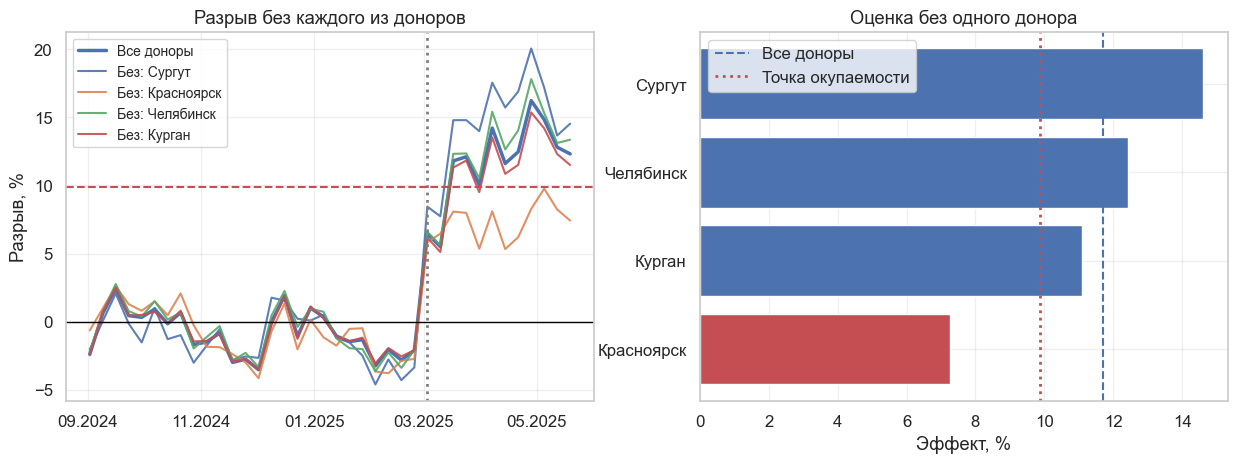

In [45]:
loo = leave_one_out(orders, TREATED, POOL)

# Проверка
assert set(loo.index) == set(first.weights[first.weights > 0.01].index)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(first.gap.index[T0 - 26:], first.gap.values[T0 - 26:], color=BLUE, lw=2.5, label="Все доноры")
for drop in loo.index:
    gap = synth(orders, TREATED, [d for d in POOL if d != drop]).gap
    axes[0].plot(gap.index[T0 - 26:], gap.values[T0 - 26:], lw=1.5, alpha=0.9, label=f"Без: {drop}")
axes[0].axvline(LAUNCH, color=GRAY, ls=":", lw=2)
axes[0].axhline(BREAK_EVEN, color=RED, ls="--", lw=1.5)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_ylabel("Разрыв, %")
axes[0].set_title("Разрыв без каждого из доноров")
axes[0].legend(fontsize=10)
axes[0].xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 3, 5, 7, 9, 11)))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
ordered = loo.sort_values()
axes[1].barh(ordered.index, ordered.values, color=[RED if v < BREAK_EVEN else BLUE for v in ordered.values])
axes[1].axvline(first_effect, color=BLUE, ls="--", label="Все доноры")
axes[1].axvline(BREAK_EVEN, color=RED, ls=":", lw=2, label="Точка окупаемости")
axes[1].set_xlabel("Эффект, %")
axes[1].set_title("Оценка без одного донора")
axes[1].legend()
loo.round(2).to_dict()

Вот первый серьёзный сигнал. Без Красноярска эффект падает до +7.3%, и это уже **ниже точки окупаемости**, а без Сургута растёт до +14.6%. Размах 7.4 п.п., и решение о раскатке зависит от одного города с весом 0.32.

Сравните с примером Абади про Германию: там все такие оценки лежат вокруг основной. У нас вывод держится на судьбе доноров. Значит, надо понять, что с ними произошло, но сначала посмотрим шире.

### Задание 13. Кривая спецификаций

Исключение по одному донору — лишь один из вариантов выбора. Аналитик решает также, какой брать блок, где заканчивать подгонку и каких доноров считать подходящими. Посмотрим сразу на всё.

Реализуйте `spec_curve(y, city, specs)`. На вход список словарей с ключами `name_pool`, `pool`, `block`, `fit_end`. Для каждого посчитайте эффект и верните таблицу со столбцами `pool`, `block`, `fit_end`, `effect`, `pre_rmspe`, отсортированную по эффекту.

In [46]:
def spec_curve(y: pd.DataFrame, city: str, specs: list) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [47]:
# @title Решение (нажмите, чтобы раскрыть)
def spec_curve(y: pd.DataFrame, city: str, specs: list) -> pd.DataFrame:
    rows = []
    for spec in specs:
        gap = synth(y, city, spec["pool"], fit_end=spec["fit_end"], block=spec["block"]).gap.values
        rows.append({"pool": spec["name_pool"], "block": spec["block"], "fit_end": spec["fit_end"],
                     "effect": gap[T0:].mean(), "pre_rmspe": rmspe(gap[:spec["fit_end"]])})
    return pd.DataFrame(rows).sort_values("effect", ignore_index=True)

Диапазон: -0.3% ... 12.4%, выше точки окупаемости 22% спецификаций
                         min  median   max
pool                                      
Без своего региона     -0.30    6.10  9.50
Все                     6.60   10.50 12.40
Половина самых похожих  3.90    6.20  7.60


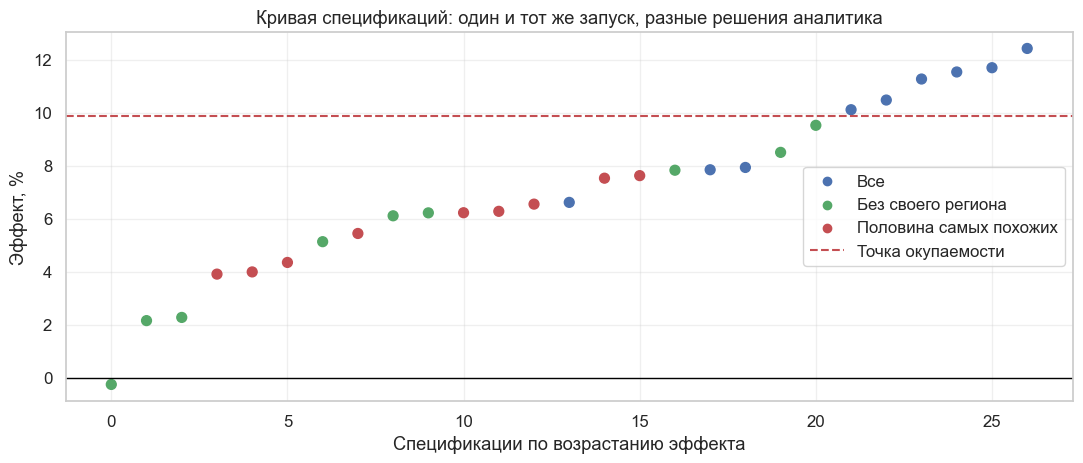

In [48]:
region_of = cities["region"]
pools = {"Все": POOL, "Без своего региона": [c for c in POOL if region_of[c] != "Урал"],
         "Половина самых похожих": list(position.loc[POOL, "level"].sub(position.loc[TREATED, "level"]).abs().sort_values().index[:28])}
specs_list = [{"name_pool": name, "pool": pool, "block": block, "fit_end": end}
              for name, pool in pools.items() for block in (2, 4, 13) for end in (T0, T0 - 4, T0 - 13)]
curve_table = spec_curve(orders, TREATED, specs_list)

# Проверка
assert len(curve_table) == len(specs_list) and curve_table["effect"].is_monotonic_increasing

fig, ax = plt.subplots(figsize=(13, 4.8))
colors = dict(zip(pools, [BLUE, GREEN, RED]))
ax.scatter(range(len(curve_table)), curve_table["effect"], c=curve_table["pool"].map(colors), s=50)
for name, color in colors.items():
    ax.scatter([], [], color=color, label=name)
ax.axhline(BREAK_EVEN, color=RED, ls="--", label="Точка окупаемости")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Спецификации по возрастанию эффекта")
ax.set_ylabel("Эффект, %")
ax.set_title("Кривая спецификаций: один и тот же запуск, разные решения аналитика")
ax.legend()
print(f"Диапазон: {curve_table['effect'].min():.1f}% ... {curve_table['effect'].max():.1f}%, выше точки окупаемости {100 * (curve_table['effect'] > BREAK_EVEN).mean():.0f}% спецификаций")
print(curve_table.groupby("pool")["effect"].agg(["min", "median", "max"]).round(1).to_string())

Один и тот же запуск даёт оценки от −0.3% до +12.4%, и только 22% спецификаций выше точки окупаемости. Самые высокие значения приходятся на пул со всеми городами. Если убрать свой регион или взять только похожие города, медиана падает с 10.5% до 6.1–6.2%. Такая зависимость от пула говорит о проблеме с донорами, а не только о неопределённости.

### Задание 14. Цена перебора

Широкая кривая опасна не только неопределённостью. Если перебирать спецификации, пока одна не станет значимой, получится p-hacking. [Ferman, Pinto, Possebom](https://mpra.ub.uni-muenchen.de/85138/1/MPRA_paper_85138.pdf) показали, что при шести популярных спецификациях шанс хотя бы одного значимого результата на 5% достигает примерно 13% при 12 периодах до воздействия и остаётся около 10% даже при 230 периодах.

Измерим это на наших данных, где эффекта заведомо нет: на ложных датах до анонса. Реализуйте `cherry_fpr(y, pool, ends, blocks, alpha)`. Для каждой ложной даты `end` и блока обрежьте панель до недели `end + 12`, посчитайте плацебо по всем городам `pool` и p-value каждого города по отношению RMSPE. В качестве `treated` передавайте `pool[0]`, а саму функцию `placebo_gaps` используйте для `pool[1:]`: так в таблице будут все города. Верните таблицу: доля значимых по каждому блоку и строка `any` с долей случаев, когда значим хотя бы один блок.

In [49]:
def cherry_fpr(y: pd.DataFrame, pool: list, ends: list, blocks: list, alpha: float = 0.05) -> pd.Series:
    # ВАШ КОД
    raise NotImplementedError

In [50]:
# @title Решение (нажмите, чтобы раскрыть)
def cherry_fpr(y: pd.DataFrame, pool: list, ends: list, blocks: list, alpha: float = 0.05) -> pd.Series:
    significant = []
    for end in ends:
        cut = y.iloc[:end + 12]
        by_block = {}
        for block in blocks:
            table = placebo_summary(placebo_gaps(cut, pool[1:], pool[0], fit_end=end, block=block), pool[0], end, end)
            ranks = table["ratio"].rank(ascending=False, method="max") / len(table)
            by_block[block] = ranks <= alpha
        significant.append(pd.DataFrame(by_block))
    flags = pd.concat(significant)
    result = flags.mean()
    result["any"] = flags.any(axis=1).mean()
    return result

In [51]:
cherry = cherry_fpr(orders, POOL, [60, 74, 88], [4, 13, 26])

# Проверка: перебор не может быть лучше любой отдельной спецификации
assert cherry["any"] >= cherry.drop("any").max()

cherry_view = (100 * cherry).round(1).rename(lambda k: "Хотя бы один блок" if k == "any" else f"Блок {k}")
print("Доля ложных срабатываний на уровне 5%, %:")
print(cherry_view.to_string())

Доля ложных срабатываний на уровне 5%, %:
Блок 4              3.60
Блок 13             3.60
Блок 26             3.60
Хотя бы один блок   7.10


Каждая отдельная спецификация держит уровень: 3.6%. Это потолок из-за дискретности, больше 2 городов из 56 при 5% быть не может. Выбирая лучшую из трёх, мы получаем 7.1%, почти вдвое больше. У нас перебирался только блок, а реальный перебор доноров, дат и предикторов шире.

Отсюда правило: **спецификацию фиксируем до того, как посмотрели на результат**. Мы выбрали блок на отложенных данных до запуска, так что этот выбор не зависел от эффекта. Показывать кривую спецификаций нужно, но как проверку устойчивости, а не как меню. Ferman et al. отдельно отмечают: если отчёт перечисляет все спецификации и значимость у каждой, это ещё не корректный тест.

## 8. Что метод умеет на этих данных

Мы проверяли этот запуск. Теперь проверим **сам рецепт** целиком: как он ведёт себя там, где истина известна. Статья Wildberries из источников как раз использует такую схему: A/A на направлениях без воздействия и искусственно добавленный эффект.

### Задание 15. A/A и искусственный эффект

На панели до анонса подписки нигде не было. Возьмём несколько ложных дат, и для каждой получим разрывы всех городов за 12 недель после неё. Так появится много случаев, где эффект заведомо равен нулю.

Реализуйте `aa_runs(y, pool, ends)`: верните список таблиц разрывов `placebo_gaps` для каждой ложной даты, панель обрезана до `end + 12`.

Реализуйте `aa_power(runs, ends, delta, alpha)`: добавьте к разрывам после ложной даты эффект `delta` процентов у одного города за раз и посчитайте его p-value по отношению RMSPE среди всех городов той же даты. Верните долю случаев с $p \le \alpha$. Веса заново не подбираем: воздействие на них не влияет. При `delta = 0` функция должна вернуть долю ложных срабатываний.

In [52]:
def aa_runs(y: pd.DataFrame, pool: list, ends: list) -> list:
    # ВАШ КОД
    raise NotImplementedError


def aa_power(runs: list, ends: list, delta: float, alpha: float = 0.05) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [53]:
# @title Решение (нажмите, чтобы раскрыть)
def aa_runs(y: pd.DataFrame, pool: list, ends: list) -> list:
    return [placebo_gaps(y.iloc[:end + 12], pool[1:], pool[0], fit_end=end) for end in ends]


def aa_power(runs: list, ends: list, delta: float, alpha: float = 0.05) -> float:
    hits = []
    for gaps, end in zip(runs, ends):
        values = gaps.values
        pre = np.sqrt((values[:end] ** 2).mean(axis=0))
        post = np.sqrt((values[end:] ** 2).mean(axis=0))
        ratios = post / pre
        boosted = np.sqrt(((values[end:] + delta) ** 2).mean(axis=0)) / pre
        for i in range(values.shape[1]):
            others = np.delete(ratios, i)
            hits.append((1 + (others >= boosted[i]).sum()) / len(ratios) <= alpha)
    return float(np.mean(hits))

Смещение оценки при нуле, п.п.                               -0.01
SD оценки при нуле, п.п.                                      1.87
Ложные срабатывания: отношение RMSPE                          0.04
Ложные срабатывания: t-тест по неделям                        0.51
Ложные срабатывания: t-тест по сглаженным неделям (4 нед.)    0.70
MDE при мощности 80%: 6.0%, мощность на точке окупаемости: 0.97


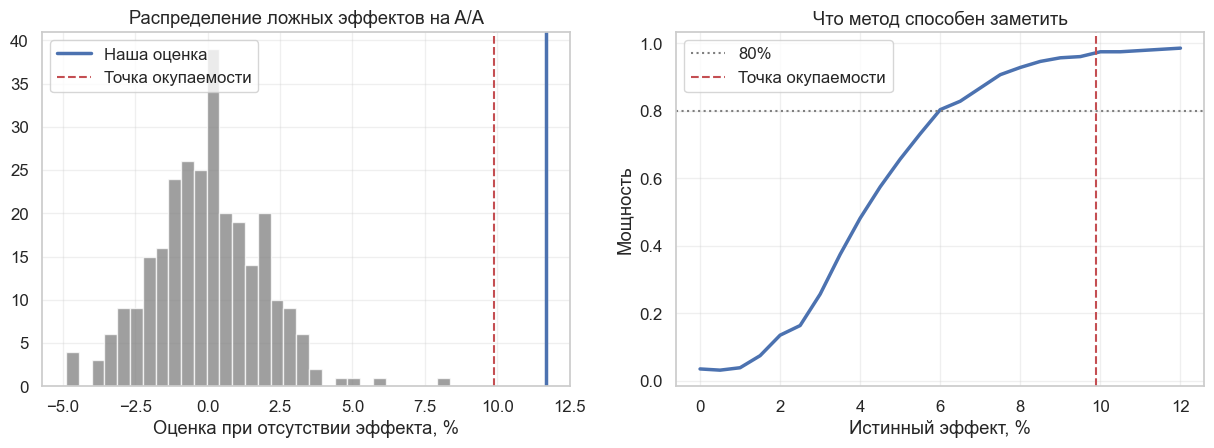

In [54]:
AA_ENDS = [52, 61, 70, 79, 88]
runs = aa_runs(orders, POOL, AA_ENDS)

# Проверка
assert len(runs) == len(AA_ENDS) and runs[0].shape == (AA_ENDS[0] + 12, len(POOL))
assert aa_power(runs, AA_ENDS, 30.0) > aa_power(runs, AA_ENDS, 0.0)

deltas = np.arange(0, 12.5, 0.5)
power_curve = pd.Series([aa_power(runs, AA_ENDS, d) for d in deltas], index=deltas)
aa_effects = np.concatenate([g.values[e:].mean(axis=0) for g, e in zip(runs, AA_ENDS)])


def t_test_fpr(smooth: int = 1, alpha: float = 0.05) -> float:
    """Доля ложных срабатываний наивного t-теста по неделям разрыва."""
    rejected = []
    for gaps, end in zip(runs, AA_ENDS):
        series = gaps.rolling(smooth, min_periods=1).mean().values[end:]
        rejected.append(stats.ttest_1samp(series, 0, axis=0).pvalue < alpha)
    return float(np.concatenate(rejected).mean())


aa_table = pd.Series({
    "Смещение оценки при нуле, п.п.": aa_effects.mean(),
    "SD оценки при нуле, п.п.": aa_effects.std(),
    "Ложные срабатывания: отношение RMSPE": aa_power(runs, AA_ENDS, 0.0),
    "Ложные срабатывания: t-тест по неделям": t_test_fpr(),
    "Ложные срабатывания: t-тест по сглаженным неделям (4 нед.)": t_test_fpr(4)})
mde = float(power_curve[power_curve >= 0.8].index.min())
print(aa_table.round(3).to_string())
print(f"MDE при мощности 80%: {mde:.1f}%, мощность на точке окупаемости: {np.interp(BREAK_EVEN, deltas, power_curve):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].hist(aa_effects, bins=30, color=GRAY, alpha=0.75)
axes[0].axvline(first_effect, color=BLUE, lw=2.5, label="Наша оценка")
axes[0].axvline(BREAK_EVEN, color=RED, ls="--", label="Точка окупаемости")
axes[0].set_xlabel("Оценка при отсутствии эффекта, %")
axes[0].set_title("Распределение ложных эффектов на A/A")
axes[0].legend()
axes[1].plot(power_curve.index, power_curve.values, color=BLUE, lw=2.5)
axes[1].axhline(0.8, color=GRAY, ls=":", label="80%")
axes[1].axvline(BREAK_EVEN, color=RED, ls="--", label="Точка окупаемости")
axes[1].set_xlabel("Истинный эффект, %")
axes[1].set_ylabel("Мощность")
axes[1].set_title("Что метод способен заметить")
axes[1].legend();

Сам рецепт в порядке:

* **Смещения нет**, SD оценки при нулевом эффекте 1.9 п.п. Наша оценка +11.7% лежит далеко за пределами A/A, так что это не случайный шум.
* **Плацебо держит уровень**: 4% ложных срабатываний при 5%.
* **MDE равен 6%**, а на точке окупаемости мощность 97%. Значит, отличить окупаемый эффект от нуля метод может, а вот эффект меньше 6% заметит не всегда.
* **T-тест по неделям непригоден**: 51% ложных срабатываний вместо 5%, а после сглаживания 70%.

Последний пункт стоит соотнести с [кейсом Wildberries](https://habr.com/ru/companies/wildberries/articles/885602/). Там сделано много верного: A/A на направлениях без воздействия, искусственные эффекты, оценка MDE в 5–15%, близкая к нашей. Но значимость появилась только после сглаживания 7-дневным средним, и проверялась она t-тестом по дням. Наша таблица показывает, почему так делать нельзя: сглаживание увеличивает автокорреляцию, и тест начинает видеть то, чего нет. Это наш вывод на наших данных, а не утверждение об ошибочности их результата.

Важное ограничение: A/A показывает, что метод молчит, **когда доноры чисты**. О том, что случилось с донорами именно после запуска, он ничего не говорит.

### Задание 16. Контрольная метрика

Все проверки выше работали с той же метрикой, в которой мы ищем эффект. У нас есть и другая: корпоративные заказы. Подписка доступна только физлицам, поэтому на `b2b_orders` она влиять не должна. Если у синтетики всё в порядке, тот же набор весов должен показать там нулевой разрыв.

Важно использовать **те же веса**, а не подбирать новые: мы проверяем именно эту синтетику. Реализуйте `control_gap(y_control, city, weights, fit_end)`: посчитайте разрыв в процентах на тех же весах и вычтите его среднее до `fit_end`, потому что по этой метрике уровни не подгонялись.

Для оценки шума возьмём средние по скользящим окнам из 12 недель в предпериоде.

In [55]:
def control_gap(y_control: pd.DataFrame, city: str, weights: pd.Series, fit_end: int = T0) -> pd.Series:
    # ВАШ КОД
    raise NotImplementedError

In [56]:
# @title Решение (нажмите, чтобы раскрыть)
def control_gap(y_control: pd.DataFrame, city: str, weights: pd.Series, fit_end: int = T0) -> pd.Series:
    synthetic = y_control[weights.index].values @ weights.values
    gap = 100 * (y_control[city] - synthetic) / synthetic
    return gap - gap.iloc[:fit_end].mean()

Разрыв по B2B после запуска: +6.4%, шум 12-недельных средних 1.2%, z = 5.2


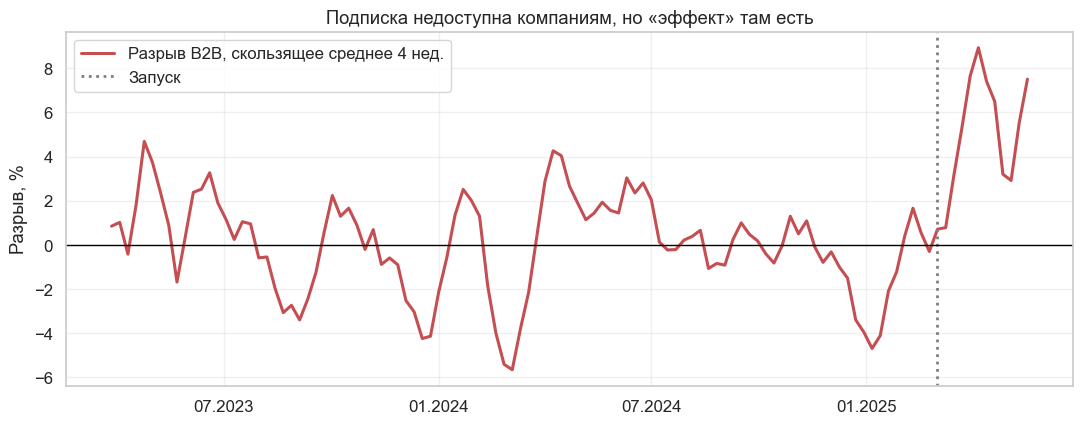

In [57]:
# Проверка: если контрольная метрика пропорциональна донорам, разрыв нулевой
check_w = pd.Series([0.5, 0.5], index=["a", "b"])
check = pd.DataFrame({"a": np.arange(1.0, 21), "b": np.arange(1.0, 21), "c": np.arange(1.0, 21) * 1.3})
assert np.allclose(control_gap(check, "c", check_w, 10), 0)


def control_check(weights: pd.Series, fit_end: int = T0) -> tuple:
    """Возвращает разрыв контрольной метрики, эффект после запуска и SD 12-недельных средних до запуска."""
    gap = control_gap(b2b, TREATED, weights, fit_end)
    noise = gap.iloc[:fit_end].rolling(12).mean().dropna().std()
    return gap, gap.values[T0:].mean(), noise


first_b2b, first_b2b_effect, b2b_noise = control_check(first.weights)
print(f"Разрыв по B2B после запуска: {first_b2b_effect:+.1f}%, шум 12-недельных средних {b2b_noise:.1f}%, z = {first_b2b_effect / b2b_noise:.1f}")

fig, ax = plt.subplots(figsize=(13, 4.6))
ax.plot(first_b2b.index, first_b2b.rolling(4).mean(), color=RED, lw=2.2, label="Разрыв B2B, скользящее среднее 4 нед.")
ax.axvline(LAUNCH, color=GRAY, ls=":", lw=2, label="Запуск")
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Разрыв, %")
ax.set_title("Подписка недоступна компаниям, но «эффект» там есть")
ax.legend()
date_axis(ax);

Вот и второй сигнал. Подписка недоступна компаниям, но разрыв по B2B вырос на +6.4% при шуме 1.2 п.п., это $z = 5.2$. Настоящего эффекта тут быть не может, значит, **синтетика упала сама**, и основная метрика завышена той же ошибкой.

Эта проверка — единственная, что могла отличить подписку от проблемы с контролем. Если бы контрольная метрика выросла при чистых донорах, это указывало бы на другое событие в самом Екатеринбурге, например уход конкурента. Такое событие не поймали бы ни плацебо, ни бэкдейтинг, ни исключение доноров.

Идём к операционной команде и просим журнал всех событий в городах за последние полгода. Выберем из него доноров нашей синтетики.

In [58]:
events = load_csv("events.csv", parse_dates=["week"])
print(f"Всего записей: {len(events)}, доноров с весом > 1%: {(first.weights > 0.01).sum()}")
in_synth = events.assign(weight=events["city"].map(first.weights).fillna(0).round(3))
in_synth

Всего записей: 10, доноров с весом > 1%: 4


,city,week,type,description,weight
0,Омск,2024-05-27,Обновление приложения,Новый экран корзины для всех городов,0.00
1,Казань,2024-09-30,Промо,Недельная скидка на первый заказ,0.00
2,Екатеринбург,2025-02-03,Коммуникации,Анонс подписки в приложении и рассылке,0.00
3,Екатеринбург,2025-03-03,Запуск,Платная подписка с бесплатной доставкой,0.00
4,Челябинск,2025-03-03,Операции,Часть курьеров перераспределена в соседний город,0.14
5,Курган,2025-03-03,Операции,Часть курьеров перераспределена в соседний город,0.07
6,Тюмень,2025-03-03,Операции,Часть курьеров перераспределена в соседний город,0.00
7,Сочи,2025-03-10,Промо,Сезонная реклама на билбордах,0.00
8,Красноярск,2025-03-24,Инцидент,"Закрыт крупный склад, зона доставки сократилась",0.32
9,Томск,2025-04-07,Операции,Плановая смена подрядчика сортировки,0.00


Журнал объясняет всё, что мы нашли:

* **Красноярск**, вес 0.32: на 3-й неделе закрылся крупный склад.
* **Челябинск и Курган**, суммарный вес 0.21: в день запуска часть их курьеров перебросили в Екатеринбург. Это прямая интерференция: сам запуск ухудшил контроль.
* **Анонс** за 4 недели до запуска объясняет провал перед стартом.

Больше половины синтетики просело после запуска по причинам, не связанным с подпиской, и разрыв вырос сам. Продакт не обманывал: сама подписка нигде больше не менялась. Просто операционные решения не считались частью эксперимента. Поэтому вопрос к команде должен звучать не «что-то менялось?», а «покажите журнал».

## 9. Исправляем анализ

Теперь мы знаем причины, и правки следуют из контекста, а не из желания получить нужное число:

* **Убираем из доноров** все города с операционными событиями после запуска: соседей, потерявших курьеров, город с закрытым складом и заодно Томск, хотя его событие выглядит безобидным. Простое правило надёжнее ручного отбора. Это прямое требование Абади: в пуле не должно быть городов с собственными шоками и затронутых воздействием.
* **Заканчиваем подгонку до анонса**, на неделе `T0 - 4`.
* **Оцениваем эффект на 12 неделях после запуска**. Недели между анонсом и запуском не используем ни для подгонки, ни для оценки.

**Вопрос.** Мы выбрасываем доноров, увидев результат. Чем это отличается от p-hacking из раздела 7?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Причина исключения проверяема и не зависит от величины эффекта: журнал показывает события, случившиеся независимо от нашего анализа. Мы убрали бы эти города, даже если бы их удаление увеличило эффект. Перебор устроен наоборот: критерий отбора — само значение p-value. Тем не менее граница тонкая, поэтому в отчёте надо показать обе оценки и объяснить, что изменилось и почему. Правила для будущих запусков лучше зафиксировать заранее.

</details>

### Задание 17. Финальная оценка

Соберите очищенный пул `CLEAN_POOL` и посчитайте для него всё заново: синтетику `clean` с `fit_end = FIT_END`, плацебо `clean_table`, конформный интервал на панели без недель анонса и исключение доноров. Эффект считайте на неделях после `T0`.

In [59]:
AFFECTED = events.loc[events["type"].isin(["Операции", "Инцидент"]) & (events["week"] >= LAUNCH), "city"].tolist()
FIT_END = T0 - 4
# ВАШ КОД: CLEAN_POOL, clean, clean_effect, clean_gaps, clean_table, clean_low, clean_high, clean_loo

In [60]:
# @title Решение (нажмите, чтобы раскрыть)
AFFECTED = events.loc[events["type"].isin(["Операции", "Инцидент"]) & (events["week"] >= LAUNCH), "city"].tolist()
FIT_END = T0 - 4
CLEAN_POOL = [c for c in POOL if c not in AFFECTED]

clean = synth(orders, TREATED, CLEAN_POOL, fit_end=FIT_END)
clean_effect = float(clean.gap.values[T0:].mean())
clean_gaps = placebo_gaps(orders, CLEAN_POOL, TREATED, fit_end=FIT_END)
clean_table = placebo_summary(clean_gaps, TREATED, fit_end=FIT_END, post_start=T0)

keep = np.r_[np.arange(FIT_END), np.arange(T0, len(orders))]
donut = orders.iloc[keep]
donut_post = np.arange(len(keep)) >= FIT_END
clean_low, clean_high, clean_curve = conformal_ci(donut[TREATED].values, donut[CLEAN_POOL].values, donut_post, theta_grid)
clean_loo = leave_one_out(orders, TREATED, CLEAN_POOL, fit_end=FIT_END, post_start=T0)

Исключены: ['Челябинск', 'Курган', 'Тюмень', 'Красноярск', 'Томск']
Доноры: {'Сургут': 0.481, 'Пенза': 0.266, 'Омск': 0.101, 'Новосибирск': 0.083, 'Мурманск': 0.07}
Эффект: +4.2%, 90%-интервал [-2.0%; 7.0%]
p-value плацебо: 0.077 по отношению RMSPE, 0.058 по эффекту, городов 52
Без одного донора: 2.4% ... 4.5%
Разрыв B2B: -0.0% при шуме 1.0%
Разрыв в неделях анонса: -4.6%


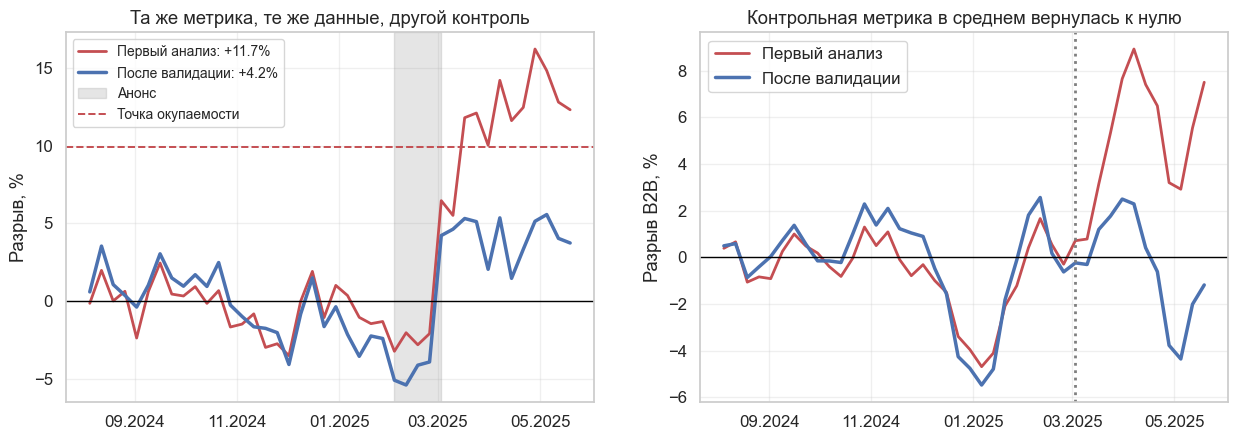

In [61]:
# Проверка
assert not set(AFFECTED) & set(CLEAN_POOL) and len(CLEAN_POOL) < len(POOL)
assert clean_gaps.shape[1] == len(CLEAN_POOL) + 1

clean_b2b, clean_b2b_effect, clean_b2b_noise = control_check(clean.weights, FIT_END)
print("Исключены:", AFFECTED)
print("Доноры:", clean.weights[clean.weights > 0.01].sort_values(ascending=False).round(3).to_dict())
print(f"Эффект: {clean_effect:+.1f}%, 90%-интервал [{clean_low:.1f}%; {clean_high:.1f}%]")
print(f"p-value плацебо: {placebo_p(clean_table, TREATED):.3f} по отношению RMSPE, {placebo_p(clean_table, TREATED, 'effect'):.3f} по эффекту, городов {len(clean_table)}")
print(f"Без одного донора: {clean_loo.min():.1f}% ... {clean_loo.max():.1f}%")
print(f"Разрыв B2B: {clean_b2b_effect:+.1f}% при шуме {clean_b2b_noise:.1f}%")
print(f"Разрыв в неделях анонса: {clean.gap.values[FIT_END:T0].mean():+.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(first.gap.index[T0 - 30:], first.gap.values[T0 - 30:], color=RED, lw=2, label=f"Первый анализ: +{first_effect:.1f}%")
axes[0].plot(clean.gap.index[T0 - 30:], clean.gap.values[T0 - 30:], color=BLUE, lw=2.5, label=f"После валидации: +{clean_effect:.1f}%")
axes[0].axvspan(orders.index[FIT_END], LAUNCH, color=GRAY, alpha=0.2, label="Анонс")
axes[0].axhline(BREAK_EVEN, color=RED, ls="--", lw=1.4, label="Точка окупаемости")
axes[0].axhline(0, color="black", lw=1)
axes[0].set_ylabel("Разрыв, %")
axes[0].set_title("Та же метрика, те же данные, другой контроль")
axes[0].legend(fontsize=10)
axes[1].plot(first_b2b.index[T0 - 30:], first_b2b.rolling(4).mean().values[T0 - 30:], color=RED, lw=2, label="Первый анализ")
axes[1].plot(clean_b2b.index[T0 - 30:], clean_b2b.rolling(4).mean().values[T0 - 30:], color=BLUE, lw=2.5, label="После валидации")
axes[1].axvline(LAUNCH, color=GRAY, ls=":", lw=2)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_ylabel("Разрыв B2B, %")
axes[1].set_title("Контрольная метрика в среднем вернулась к нулю")
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 3, 5, 7, 9, 11)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))

Эффект упал с +11.7% до **+4.2%**, а картина стала другой:

* **Контрольная метрика** вернулась к нулю: 0.0% при шуме 1.0 п.п.
* **Исключение доноров** теперь даёт от 2.4% до 4.5%: все оценки по одну сторону от точки окупаемости.
* **90%-интервал** равен [−2%; 7%] и целиком лежит ниже окупаемости +9.9%.
* **Плацебо** ухудшилось: p-value 0.08 по отношению RMSPE и 0.06 по эффекту. Это ожидаемо: эффект ниже MDE в 6%, и метод видит его не всегда. Честная оценка оказалась менее значимой, чем завышенная.
* **Провал в неделях анонса** теперь виден ясно: −4.6%. Часть клиентов откладывала заказы, значит, часть роста в начале могла быть простым переносом.

## 10. Synthetic DiD

[Arkhangelsky et al. (2021)](https://arxiv.org/abs/1812.09970) соединили обе идеи. DiD допускает постоянную разницу уровней, но веса у всех одинаковые. Синтетический контроль подбирает веса, но требует совпадения уровней. Synthetic DiD (SDID) берёт от каждого лучшее и добавляет ещё один шаг: веса **по времени**.

**Веса городов** похожи на синтетический контроль, но со свободным членом $\omega_0$ и штрафом:

$$\hat\omega = \arg\min_{\omega_0,\ \omega \ge 0,\ \sum_j \omega_j = 1}\ \sum_{t \le T_0}\Big(\omega_0 + \sum_j \omega_j Y_{jt} - Y_{1t}\Big)^2 + \zeta^2 T_0 \lVert\omega\rVert_2^2$$

Свободный член означает, что нужна параллельность, а не совпадение уровней. Штраф разносит веса по большему числу доноров и делает решение единственным. Его размер берётся из данных: $\zeta = (N_{tr} T_{post})^{1/4}\hat\sigma$, где $\hat\sigma$ — стандартное отклонение недельных приращений доноров до запуска.

**Веса недель** ищут такие недели до запуска, которые похожи на период после него:

$$\hat\lambda = \arg\min_{\lambda_0,\ \lambda \ge 0,\ \sum_t \lambda_t = 1}\ \sum_{j}\Big(\lambda_0 + \sum_{t \le T_0} \lambda_t Y_{jt} - \bar Y_{j}^{\,post}\Big)^2$$

**Оценка** — разность разностей с этими весами:

$$\hat\tau = \Big(\bar Y_1^{\,post} - \sum_t \hat\lambda_t Y_{1t}\Big) - \sum_j \hat\omega_j\Big(\bar Y_j^{\,post} - \sum_t \hat\lambda_t Y_{jt}\Big)$$

Если взять равные веса городов и недель, получится обычный DiD. Если убрать свободный член, штраф и вычитание предпериода, получится синтетический контроль.

### Задание 18. Реализация

Реализуйте `sdid(Y1, Y0, n_pre)`. Здесь `Y1` — ряд города, `Y0` — матрица доноров (строки — периоды), первые `n_pre` периодов идут до запуска, остальные после. Верните `(tau, omega, lam, zeta)`.

Подсказки:

* Свободный член уходит, если центрировать: столбцы $Y_0$ и $Y_1$ по времени для $\omega$, строки по городам для $\lambda$.
* Штраф можно добавить через готовую `fit_weights`: припишите к матрице $\sqrt{\zeta^2 T_0}\,I$, а к целевому вектору нули.
* Для $\hat\sigma$ используйте делитель $N_{co}(T_{pre}-1) - 1$. Для $\lambda$ добавьте малый штраф с $\zeta_\lambda = 10^{-6}\hat\sigma$ ради единственности решения.

In [62]:
def sdid(Y1: np.ndarray, Y0: np.ndarray, n_pre: int) -> tuple:
    # ВАШ КОД
    raise NotImplementedError

In [63]:
# @title Решение (нажмите, чтобы раскрыть)
def sdid(Y1: np.ndarray, Y0: np.ndarray, n_pre: int) -> tuple:
    pre, post = Y0[:n_pre], Y0[n_pre:]
    n_co, n_post = Y0.shape[1], len(Y0) - n_pre
    steps = np.diff(pre, axis=0)
    sigma = np.sqrt(((steps - steps.mean()) ** 2).sum() / (n_co * (n_pre - 1) - 1))
    zeta = n_post ** 0.25 * sigma

    centered = pre - pre.mean(axis=0)
    target = Y1[:n_pre] - Y1[:n_pre].mean()
    ridge = np.sqrt(zeta ** 2 * n_pre) * np.eye(n_co)
    omega = fit_weights(np.r_[target, np.zeros(n_co)], np.vstack([centered, ridge]))

    by_unit = pre.T - pre.T.mean(axis=0)
    post_mean = post.mean(axis=0)
    ridge_time = 1e-6 * sigma * np.sqrt(n_co) * np.eye(n_pre)
    lam = fit_weights(np.r_[post_mean - post_mean.mean(), np.zeros(n_pre)], np.vstack([by_unit, ridge_time]))

    tau = (Y1[n_pre:].mean() - lam @ Y1[:n_pre]) - omega @ (post_mean - pre.T @ lam)
    return float(tau), omega, lam, float(zeta)

Проверим реализацию на независимом эталоне. Статья приводит для Калифорнии оценки, а данные у нас есть из лекции 2.09. В опубликованной версии статьи и у [Clarke et al.](https://arxiv.org/abs/2301.11859), которые её воспроизводят, SDID равен −15.6. Сверяйтесь именно с ними: в черновике на arXiv от сентября 2021 года стоит −13.4, и штраф там записан иначе.

In [64]:
smoke = load_csv("california_cigsale.csv").pivot(index="year", columns="state", values="cigsale")
CALIFORNIA, N_PRE = 3, int((smoke.index < 1989).sum())
Y1_ca, Y0_ca = smoke[CALIFORNIA].values, smoke.drop(columns=CALIFORNIA).values
tau_ca, omega_ca, lam_ca, zeta_ca = sdid(Y1_ca, Y0_ca, N_PRE)
did_ca = (Y1_ca[N_PRE:].mean() - Y1_ca[:N_PRE].mean()) - (Y0_ca[N_PRE:].mean() - Y0_ca[:N_PRE].mean())
weights_ca = fit_weights(Y1_ca[:N_PRE], Y0_ca[:N_PRE])
sc_ca = (Y1_ca[N_PRE:] - Y0_ca[N_PRE:] @ weights_ca).mean()

# Проверка: сверка с опубликованными −27.3 и −15.6
assert abs(did_ca + 27.35) < 0.05 and abs(tau_ca + 15.60) < 0.05
print(f"DiD {did_ca:.2f}, SC {sc_ca:.2f}, SDID {tau_ca:.2f}")
print("Веса лет, которые отобрал SDID:", dict(zip(smoke.index[:N_PRE][lam_ca > 0.01], lam_ca[lam_ca > 0.01].round(3))))

DiD -27.35, SC -19.51, SDID -15.61
Веса лет, которые отобрал SDID: {1986: np.float64(0.367), 1987: np.float64(0.206), 1988: np.float64(0.427)}


DiD и SDID совпали с опубликованными −27.3 и −15.6. Реализация верна. SC отличается на 0.1 от опубликованных −19.6: в статье веса считаются с другими настройками штрафа, а для нас здесь важнее не SC, а сам SDID. Веса лет собрались на 1986–1988 годах: SDID сравнивает период после закона с годами прямо перед ним.

### Задание 19. Плацебо-дисперсия

При одной обработанной единице обычные способы не работают. [Clarke et al.](https://arxiv.org/abs/2301.11859) прямо пишут: джекнайф при одной обработанной единице не определён, бутстрап разрешён только при нескольких, и единственный подходящий вариант — плацебо (алгоритм 4 у Arkhangelsky et al.).

Реализуйте `sdid_placebo_se(y, pool, keep, n_pre)`. Панель берётся по неделям `keep`. Для каждого города из `pool` сделайте вид, что запустили там, донорами возьмите остальные города `pool`, посчитайте оценку в процентах от контрфактического уровня: $100 \hat\tau / (\bar Y^{\,post} - \hat\tau)$. Верните стандартное отклонение оценок.

Цена этого способа названа в статье: он опирается на **одинаковый шум у обработанного города и доноров**. Без такого предположения при одной обработанной единице дисперсию оценить нельзя.

In [65]:
def sdid_placebo_se(y: pd.DataFrame, pool: list, keep: np.ndarray, n_pre: int) -> float:
    # ВАШ КОД
    raise NotImplementedError

In [66]:
# @title Решение (нажмите, чтобы раскрыть)
def sdid_percent(Y1: np.ndarray, Y0: np.ndarray, n_pre: int) -> float:
    tau = sdid(Y1, Y0, n_pre)[0]
    return 100 * tau / (Y1[n_pre:].mean() - tau)


def sdid_placebo_se(y: pd.DataFrame, pool: list, keep: np.ndarray, n_pre: int) -> float:
    panel_kept = y.iloc[keep]
    estimates = [sdid_percent(panel_kept[city].values, panel_kept[[c for c in pool if c != city]].values, n_pre)
                 for city in pool]
    return float(np.std(estimates, ddof=1))

Эффективное число доноров: SC 3.1, SDID 25.3
Недели с наибольшим весом: {'30.12.2024': 0.49, '27.01.2025': 0.29, '06.05.2024': 0.07, '29.04.2024': 0.07}


,"Эффект, %","SE плацебо, п.п."
DiD по всем чистым донорам,6.99,NaN
Синтетический контроль,4.16,2.02
Synthetic DiD,5.27,1.92


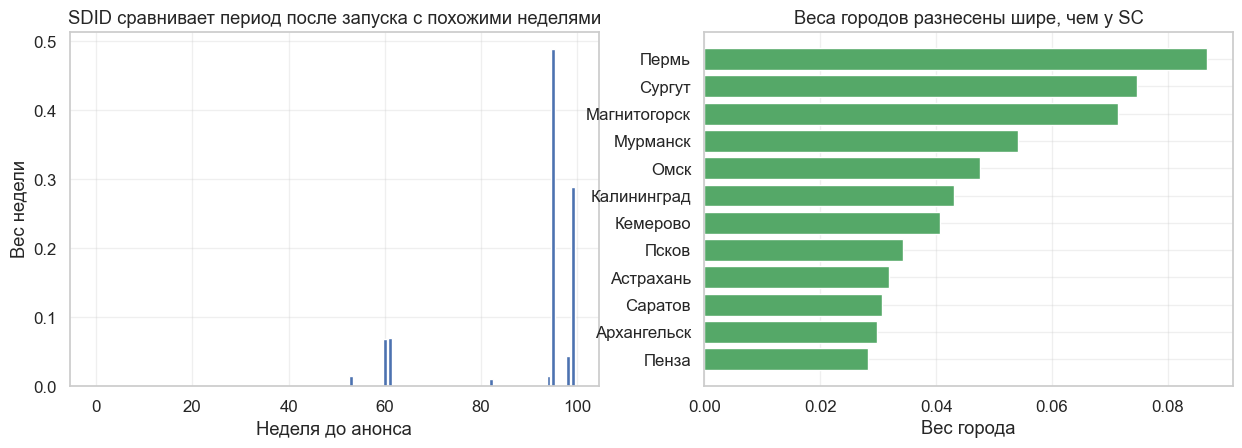

In [67]:
tau_clean, omega_clean, lam_clean, zeta_clean = sdid(donut[TREATED].values, donut[CLEAN_POOL].values, FIT_END)
sdid_effect = sdid_percent(donut[TREATED].values, donut[CLEAN_POOL].values, FIT_END)
sdid_se = sdid_placebo_se(orders, CLEAN_POOL, keep, FIT_END)
sc_se = clean_table.drop(TREATED)["effect"].std()

# Проверка
assert 0 < sdid_se < 10 and abs(omega_clean.sum() - 1) < 1e-6

naive_did = did_percent(orders, TREATED, CLEAN_POOL, T0)
compare = pd.DataFrame({
    "DiD по всем чистым донорам": [naive_did, np.nan],
    "Синтетический контроль": [clean_effect, sc_se],
    "Synthetic DiD": [sdid_effect, sdid_se]}, index=["Эффект, %", "SE плацебо, п.п."]).T
print(f"Эффективное число доноров: SC {1 / (clean.weights ** 2).sum():.1f}, SDID {1 / (omega_clean ** 2).sum():.1f}")
top_weeks = pd.Series(lam_clean, index=donut.index[:FIT_END]).sort_values(ascending=False).head(4)
print("Недели с наибольшим весом:", {f"{k:%d.%m.%Y}": round(v, 2) for k, v in top_weeks.items()})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].bar(range(len(lam_clean)), lam_clean, color=BLUE)
axes[0].set_xlabel("Неделя до анонса")
axes[0].set_ylabel("Вес недели")
axes[0].set_title("SDID сравнивает период после запуска с похожими неделями")
order_w = np.argsort(omega_clean)[::-1][:12]
axes[1].barh(np.array(CLEAN_POOL)[order_w][::-1], omega_clean[order_w][::-1], color=GREEN)
axes[1].set_xlabel("Вес города")
axes[1].set_title("Веса городов разнесены шире, чем у SC")
compare

SDID даёт +5.3% при SE 1.9 п.п., SC +4.2% при SE 2.0 п.п. Обычный DiD на тех же чистых донорах даёт +7.0%. Веса городов у SDID намного шире: эффективное число доноров 25 против 3. Поэтому он меньше зависит от судьбы отдельного города. Почти весь вес недель приходится на две недели незадолго до анонса.

Два метода опираются на разные допущения и дают близкие ответы. Это хороший признак.

Какой метод лучше на этих данных? Сравним их честно на A/A: на ложных датах истинный эффект равен нулю, поэтому среднеквадратичная ошибка оценки говорит сама за себя. Запись DiD здесь тоже нужна: это базовая линия.

In [68]:
def method_errors(y: pd.DataFrame, pool: list, ends: list) -> pd.DataFrame:
    rows = []
    for end in ends:
        cut = y.iloc[:end + 12]
        for city in pool:
            donors = [c for c in pool if c != city]
            rows.append({"SC": synth(cut, city, donors, fit_end=end).gap.values[end:].mean(),
                         "SDID": sdid_percent(cut[city].values, cut[donors].values, end),
                         "DiD": did_percent(cut, city, donors, end)})
    return pd.DataFrame(rows)


errors = method_errors(orders, CLEAN_POOL, [70, 88])
method_table = pd.DataFrame({"Смещение, п.п.": errors.mean(), "RMSE, п.п.": np.sqrt((errors ** 2).mean()),
                             "Ошибка больше 4 п.п., %": 100 * (errors.abs() > 4).mean()})
method_table

,"Смещение, п.п.","RMSE, п.п.","Ошибка больше 4 п.п., %"
SC,0.07,1.82,3.92
SDID,-0.08,1.96,2.94
DiD,-0.10,3.24,25.49


SC и SDID здесь наравне: RMSE 1.8 и 2.0 п.п., большие ошибки примерно в 3–4% случаев. DiD заметно хуже: RMSE 3.2 п.п., и в четверти случаев он ошибается больше чем на 4 п.п. Объявлять победителя между SC и SDID по такому сравнению не стоит: это две ложные даты и 102 случая. Практический вывод проще: считайте оба и смотрите, согласны ли они.

## 11. Паспорт валидации и решение

### Задание 20. Паспорт

Соберём все проверки в одну функцию, которую можно применять к любому будущему запуску. Реализуйте `validation_passport(y, control, city, pool, fit_end, post_start, threshold)`. Она должна вернуть таблицу со столбцами «Проверка», «Значение», «Статус». Статус принимает значения ✅, ⚠️ или ❌.

| Проверка | ✅ | ⚠️ | ❌ |
|---|---|---|---|
| Подгонка: RMSPE до запуска, % | < 2.5 | 2.5–5 | > 5 |
| Отложенная проверка: RMSPE на последних 22 неделях при подгонке на остальных против лучшего простого прогноза | лучше | хуже до 1.5 раза | хуже более чем в 1.5 раза |
| Концентрация: вес крупнейшего донора | < 0.5 | 0.5–0.8 | > 0.8 |
| Плацебо: p-value по отношению RMSPE | ≤ 0.05 | ≤ 0.1 | > 0.1 |
| Бэкдейтинг: средний разрыв после `fit_end - 26` | модуль < 2 | 2–4 | > 4 |
| Исключение доноров: размах оценок, п.п. | < 2 | 2–4 | > 4 |
| Контрольная метрика: $\lvert z \rvert$ | < 2 | 2–3 | > 3 |

Пороги условны, их надо подбирать под свою метрику. Смысл не в них, а в том, что все проверки выполняются всегда и в заранее известном порядке.

In [69]:
def validation_passport(y: pd.DataFrame, control: pd.DataFrame, city: str, pool: list,
                        fit_end: int = T0, post_start: int = T0) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError

In [70]:
# @title Решение (нажмите, чтобы раскрыть)
def status(value: float, good: float, bad: float) -> str:
    return "✅" if value < good else ("⚠️" if value <= bad else "❌")


def validation_passport(y: pd.DataFrame, control: pd.DataFrame, city: str, pool: list,
                        fit_end: int = T0, post_start: int = T0) -> pd.DataFrame:
    fit = synth(y, city, pool, fit_end=fit_end)
    pre_error = rmspe(fit.gap.values[:fit_end])

    holdout_errors = holdout_report(y, city, pool, fit_end - 22, fit_end)
    best_simple = min(holdout_errors["Среднее доноров"], holdout_errors["Сезонный наивный"])
    holdout_ratio = holdout_errors["Синтетика"] / best_simple

    table = placebo_summary(placebo_gaps(y, pool, city, fit_end=fit_end), city, fit_end, post_start)
    p_value = placebo_p(table, city)

    early = synth(y, city, pool, fit_end=fit_end - 26).gap.values[fit_end - 26:fit_end].mean()
    loo_values = leave_one_out(y, city, pool, fit_end, post_start)
    effect = fit.gap.values[post_start:].mean()
    loo_range = float(max(loo_values.max(), effect) - min(loo_values.min(), effect))

    gap = control_gap(control, city, fit.weights, fit_end)
    noise = gap.iloc[:fit_end].rolling(12).mean().dropna().std()
    control_z = abs(gap.values[post_start:].mean()) / noise

    rows = [("Подгонка: RMSPE до запуска, %", pre_error, status(pre_error, 2.5, 5)),
            ("Отложенная проверка: SC / лучший простой прогноз", holdout_ratio, status(holdout_ratio, 1, 1.5)),
            ("Концентрация: вес крупнейшего донора", fit.weights.max(), status(fit.weights.max(), 0.5, 0.8)),
            ("Плацебо: p-value", p_value, status(p_value, 0.05 + 1e-9, 0.1)),
            ("Бэкдейтинг: средний разрыв, п.п.", early, status(abs(early), 2, 4)),
            ("Исключение доноров: размах, п.п.", loo_range, status(loo_range, 2, 4)),
            ("Контрольная метрика: |z|", control_z, status(control_z, 2, 3))]
    return pd.DataFrame(rows, columns=["Проверка", "Значение", "Статус"]).set_index("Проверка")

In [71]:
passport_first = validation_passport(orders, b2b, TREATED, POOL)
passport_clean = validation_passport(orders, b2b, TREATED, CLEAN_POOL, fit_end=FIT_END)
passport_moscow = validation_passport(orders, b2b, OUTLIER, POOL)

# Проверка
assert passport_first.shape == (7, 2) and passport_moscow.loc["Подгонка: RMSPE до запуска, %", "Статус"] == "❌"

passports = pd.concat({"Первый анализ": passport_first, "После очистки": passport_clean, "Москва": passport_moscow}, axis=1)
passports

Первый анализ         \
                                                      Значение Статус   
Проверка                                                                
Подгонка: RMSPE до запуска, %                             1.71      ✅   
Отложенная проверка: SC / лучший простой прогноз          0.62      ✅   
Концентрация: вес крупнейшего донора                      0.46      ✅   
Плацебо: p-value                                          0.02      ✅   
Бэкдейтинг: средний разрыв, п.п.                         -1.65      ✅   
Исключение доноров: размах, п.п.                          7.36      ❌   
Контрольная метрика: |z|                                  5.25      ❌   

                                                 После очистки         \
                                                      Значение Статус   
Проверка                                                                
Подгонка: RMSPE до запуска, %                             1.75      ✅   
Отложенная проверка: SC / лучший простой прогноз          0.95      ✅   
Концентрация: вес крупнейшего донора                      0.48      ✅   
Плацебо: p-value                                          0.08     ⚠️   
Бэкдейтинг: средний разрыв, п.п.                         -0.73      ✅   
Исключение доноров: размах, п.п.                          2.03     ⚠️   
Контрольная метрика: |z|                                  0.01      ✅   

                                                   Москва         
                                                 Значение Статус  
Проверка                                                          
Подгонка: RMSPE до запуска, %                       99.91      ❌  
Отложенная проверка: SC / лучший простой прогноз    34.05      ❌  
Концентрация: вес крупнейшего донора                 1.00      ❌  
Плацебо: p-value                                     0.46      ❌  
Бэкдейтинг: средний разрыв, п.п.                   124.27      ❌  
Исключение доноров: размах, п.п.                    15.19      ❌  
Контрольная метрика: |z|                             3.68      ❌

Посмотрите на первый столбец. **Первый анализ прошёл пять проверок из семи**, включая подгонку, отложенные данные и плацебо. Его завалили только исключение доноров и контрольная метрика. Если бы мы ограничились стандартным набором из лекции, завышенная вдвое оценка ушла бы к совету директоров.

После очистки красных строк нет, но есть две жёлтые: плацебо, потому что эффект ниже MDE, и размах оценок 2.03 п.п., едва за порогом. Жёлтый цвет — это не повод подкручивать анализ, а часть честного отчёта.

Для Москвы паспорт красный уже на первых строках. Дальше читать его незачем.

### Раскрываем истину

Данные синтетические, поэтому правильный ответ известен. Он лежит в `truth.csv`, а в генераторе зашиты все заложенные проблемы. Посмотрим, кто оказался ближе.

Истинный средний эффект: +5.23%, за последние 4 недели: +5.97%, точка окупаемости: +9.9%
Оценка SC за последние 4 недели: +4.61%
Лишние заказы в неделю                          3,520.00
Маржа с них, ₽ в неделю                       528,038.00
Стоимость бесплатной доставки, ₽ в неделю   1,255,676.00
Результат, ₽ в неделю                        -727,638.00
95%-интервалы по плацебо: SC [0.2%; 8.1%], SDID [1.5%; 9.0%]


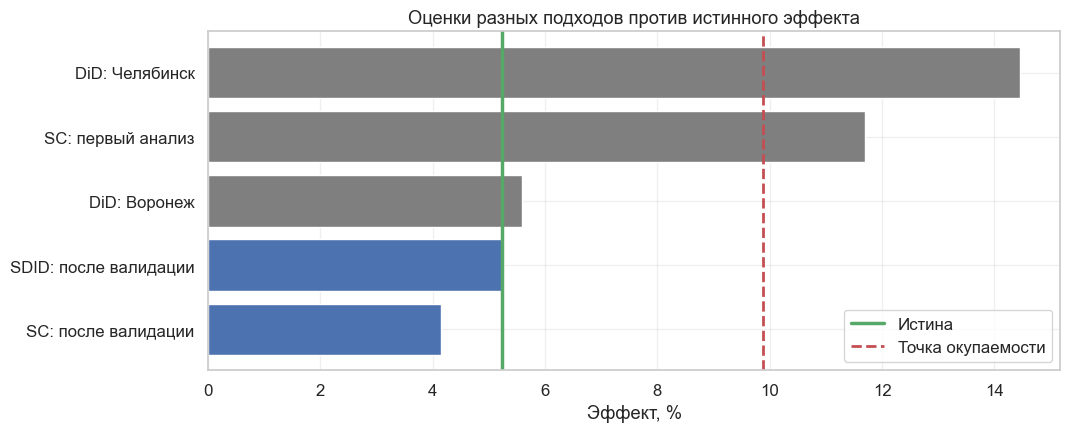

In [72]:
truth = load_csv("truth.csv", parse_dates=["week"]).set_index("week")["true_effect_pct"]
true_mean = truth.mean()
estimates = pd.Series({"DiD: Воронеж": did_table.loc["Воронеж", "Оценка на дате запуска"],
                       "DiD: Челябинск": did_table.loc["Челябинск", "Оценка на дате запуска"],
                       "SC: первый анализ": first_effect,
                       "SC: после валидации": clean_effect,
                       "SDID: после валидации": sdid_effect})
print(f"Истинный средний эффект: +{true_mean:.2f}%, за последние 4 недели: +{truth.iloc[-4:].mean():.2f}%, точка окупаемости: +{BREAK_EVEN:.1f}%")
print(f"Оценка SC за последние 4 недели: +{clean.gap.values[-4:].mean():.2f}%")

fig, ax = plt.subplots(figsize=(11, 4.4))
ordered = estimates.sort_values()
ax.barh(ordered.index, ordered.values, color=[BLUE if "после" in k else GRAY for k in ordered.index])
ax.axvline(true_mean, color=GREEN, lw=2.5, label="Истина")
ax.axvline(BREAK_EVEN, color=RED, ls="--", lw=2, label="Точка окупаемости")
ax.set_xlabel("Эффект, %")
ax.set_title("Оценки разных подходов против истинного эффекта")
ax.legend();

weekly_value = base * cities.loc[TREATED, "population"] / 1000
extra = pd.Series({"Лишние заказы в неделю": clean_effect / 100 * weekly_value,
                   "Маржа с них, ₽ в неделю": clean_effect / 100 * weekly_value * MARGIN,
                   "Стоимость бесплатной доставки, ₽ в неделю": FREE_DELIVERY_COST * cities.loc[TREATED, "population"] / 1000})
extra["Результат, ₽ в неделю"] = extra.iloc[1] - extra.iloc[2]
print(extra.round(0).to_string())
print(f"95%-интервалы по плацебо: SC [{clean_effect - 1.96 * sc_se:.1f}%; {clean_effect + 1.96 * sc_se:.1f}%], SDID [{sdid_effect - 1.96 * sdid_se:.1f}%; {sdid_effect + 1.96 * sdid_se:.1f}%]")

Истинный средний эффект равен +5.2%. Оценки после валидации, +4.2% у SC и +5.3% у SDID, оказались рядом с ним, а SC ошибся примерно на 1 п.п., что укладывается в его SE 2.0. Первый анализ завысил эффект вдвое. DiD по Воронежу случайно попал рядом, но узнать это заранее было нельзя: его ошибка на ложных датах 5.6 п.п.

Истина ниже точки окупаемости, поэтому первый анализ привёл бы к неверному решению, стоившему денег. При +4.2% маржа с лишних заказов равна примерно 528 тыс. ₽ в неделю при стоимости доставки 1.26 млн ₽, то есть минус около 730 тыс. ₽ в неделю.

**Не повезло ли нам с данными?** Мы повторили сценарий на 10 разных seed генератора, каждый раз закрывая склад у крупнейшего донора вне Урала. Первая оценка лежала в диапазоне от 8.5% до 15.1% и в 9 случаях из 10 превышала точку окупаемости. Очищенная оценка — от 1.6% до 6.7%, в среднем 4.9% при истине 5.2%, и всегда ниже окупаемости. Контрольная метрика сработала везде, $z$ от 2.4 до 8.7. Ложных срабатываний на A/A везде 3.6%, это потолок по дискретности при таком числе городов. Значит, конкретные числа зависят от данных, а вывод нет.

### Решение

**Вопрос.** Что вы скажете совету директоров?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Эффект есть, но он не окупается.** Обе оценки положительны: +4.2% у SC и +5.3% у SDID. 95%-интервалы по плацебо равны [0.2%; 8.1%] и [1.5%; 9.0%], и оба ниже точки окупаемости +9.9%.
* **Цифра +11.7% не подтвердилась.** Больше половины этого разрыва создали проблемы с донорами: закрытие склада и переброска курьеров.
* **Решение: в текущем виде на страну не раскатываем.** При нынешней экономике мы теряем около 730 тыс. ₽ в неделю только в этом городе.
* **Что можно сделать.** Пересмотреть цену подписки или условия бесплатной доставки так, чтобы точка окупаемости опустилась ниже достижимых 4–6%.
* **Чего мы не знаем.** Мы оценили только заказы за 12 недель. Влияние на удержание и долгосрочную ценность клиента этими данными не измерено, поэтому новый запуск должен отдельно на него посмотреть.
* **Следующий запуск** проводим с заранее зафиксированным планом, журналом событий и запретом перебрасывать ресурсы из городов-доноров.

</details>

### Регламент для команды

| Этап | Что делаем |
|---|---|
| **До запуска: дизайн** | Считаем MDE на A/A и сравниваем его с точкой окупаемости. Если метод не увидит нужный эффект, запуск не оценить |
| **До запуска: выбор города** | Проверяем, что город внутри облака доноров. Столица и другие выбросы для этого не годятся |
| **До запуска: план** | Фиксируем метрику, блок, пул доноров, правила исключения и контрольную метрику. На результаты до этого не смотрим |
| **Во время запуска** | Ведём журнал событий по всем городам. Записываем дату анонса, переброс ресурсов и инциденты |
| **После запуска** | Проходим все проверки паспорта в заранее известном порядке и показываем их вместе с оценкой |
| **При провале** | Ищем причину в контексте. Исключаем только то, что объясняется событиями, а не величиной результата |
| **Если подгонка плохая** | Отвечаем, что оценить нельзя. Это честный результат, а не неудача |

**Что нельзя делать:**

1. Читать t-тест по неделям разрыва как значимость.
2. Сглаживать ряд и повторять тест, пока не станет значимо.
3. Показывать лучшую спецификацию вместо заранее выбранной.
4. Считать, что малый p-value плацебо доказывает причину разрыва.
5. Верить заявлению «в других городах ничего не менялось» без журнала.

## Заключение

Подбор весов занял один раздел, всё остальное время ушло на вопрос, можно ли им верить. Вот что стоит запомнить:

1. **Метод выдаёт красивый график почти всегда.** Хорошая подгонка и значимое плацебо не отвечают на вопрос о причине разрыва.
2. **Проверки различаются по смыслу.** Подгонка и отложенные данные оценивают контрфакт, плацебо оценивает шум, исключение доноров и спецификации оценивают устойчивость, A/A оценивает сам рецепт, контрольная метрика проверяет причину.
3. **Самая сильная проверка та, что могла провалиться по независимой причине.** Здесь это контрольная метрика, на которую подписка не могла повлиять.
4. **У всех тестов есть пределы.** P-value не меньше $1/N$, город выбран не случайно, 12 недель дают широкий интервал.
5. **Сравнивать надо с бизнес-порогом, а не с нулём.** Значимость первого анализа ничего не решала: вопрос был в окупаемости.
6. **Иногда правильный ответ «оценить нельзя»,** как в случае с Москвой.
7. **SC и SDID дополняют друг друга.** Если оценки согласуются, доверие растёт, если нет, надо выяснить почему.

**Дополнительные источники.** Обзор всех условий применимости есть у [Абади (2021)](https://economics.mit.edu/sites/default/files/publications/jel.20191450.pdf), про выбор городов до запуска написано у [Abadie, Zhao](https://arxiv.org/abs/2108.02196). Augmented SC и другие расширения мы не разбирали: они полезны, когда подгонка несовершенна, см. [Ben-Michael, Feller, Rothstein](https://arxiv.org/abs/1811.04170).